# **1. DATA LOADING**

It involved loading the 4 datasets to be used which are;
1. community_scam_reports-this was created.
2. fake_job_postings.
3. phishing_URL_Dataset.
4. SMSSpamCollection.

In [139]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
import scipy.sparse as sp
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import  StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone

# Find fitted models and preprocessing objects in the notebook

from sklearn.pipeline import Pipeline
import joblib


In [7]:
# Loading the Phishing dataset
df_phishing = pd.read_csv('../../Data/Phishing_URL_Dataset.csv')

df_phishing.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [8]:
df_phishing.shape

(235795, 56)

In [9]:
df_phishing.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [10]:
df_phishing.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [11]:
df_phishing.isnull().sum()

FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

There are no missing values.

In [13]:
# Loading the fake job postings dataset
df_fake_jobs = pd.read_csv('../../Data/fake_job_postings.csv')

df_fake_jobs.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [14]:
df_phishing.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [15]:
df_fake_jobs.shape

(17880, 18)

In [16]:
df_fake_jobs.isnull().sum()

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

In [17]:
# Loading the SMS Spam Collection dataset
df_sms = pd.read_csv(
    '../../Data/SMSSpamCollection',
    sep='\t',
    header=None,
    names=['label', 'message'],
    encoding='utf-8'
)
df_sms.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [18]:
df_sms.shape

(5572, 2)

In [19]:
df_sms.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


In [20]:
df_sms.isnull().sum()

label      0
message    0
dtype: int64

In [21]:
df_sms.describe()

,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [22]:

# Creating the Community Scam Reports dataset
from pathlib import Path

# Defining the main Data folder
data_folder = Path('../../Data')
data_folder.mkdir(parents=True, exist_ok=True)

# Creating synthetic community scam reports
community_reports = [
    {
        "report_id": "CSR001",
        "report_date": "2026-10-01",
        "report_type": "Phishing",
        "platform": "SMS",
        "suspicious_url": "http://login.example.com",
        "phone_number": "SYNTHETIC_PHONE_001",
        "seller_id": "N/A",
        "description": "Message requests account login details through a suspicious link.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR002",
        "report_date": "2026-10-02",
        "report_type": "Fake Job",
        "platform": "WhatsApp",
        "suspicious_url": "http://jobs.example.org",
        "phone_number": "SYNTHETIC_PHONE_002",
        "seller_id": "N/A",
        "description": "Recruiter requests an upfront registration fee.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR003",
        "report_date": "2026-10-03",
        "report_type": "Fake Online Shop",
        "platform": "TikTok",
        "suspicious_url": "http://shop.example.net",
        "phone_number": "SYNTHETIC_PHONE_003",
        "seller_id": "SELLER_SYN_001",
        "description": "Seller requests full payment before delivery and stops responding.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR004",
        "report_date": "2026-10-04",
        "report_type": "Mobile Money Scam",
        "platform": "SMS",
        "suspicious_url": "N/A",
        "phone_number": "SYNTHETIC_PHONE_004",
        "seller_id": "N/A",
        "description": "Message claims a prize was won and requests a payment to release it.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR005",
        "report_date": "2026-10-05",
        "report_type": "Impersonation",
        "platform": "WhatsApp",
        "suspicious_url": "N/A",
        "phone_number": "SYNTHETIC_PHONE_005",
        "seller_id": "N/A",
        "description": "Account pretends to represent a trusted organization and requests personal details.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR006",
        "report_date": "2026-10-06",
        "report_type": "Phishing",
        "platform": "Email",
        "suspicious_url": "http://login.example.com",
        "phone_number": "N/A",
        "seller_id": "N/A",
        "description": "Another report identifies the same suspicious login link.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR007",
        "report_date": "2026-10-07",
        "report_type": "Fake Online Shop",
        "platform": "TikTok",
        "suspicious_url": "http://shop.example.net",
        "phone_number": "SYNTHETIC_PHONE_003",
        "seller_id": "SELLER_SYN_001",
        "description": "Repeated report about the same synthetic shop and contact identifier.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    },
    {
        "report_id": "CSR008",
        "report_date": "2026-10-08",
        "report_type": "Legitimate",
        "platform": "Website",
        "suspicious_url": "https://www.example.com",
        "phone_number": "N/A",
        "seller_id": "SELLER_SYN_002",
        "description": "Synthetic example of a normal website report with no suspicious indicators.",
        "verification_status": "Unverified",
        "is_suspicious": 0
    },
    {
        "report_id": "CSR009",
        "report_date": "2026-10-09",
        "report_type": "Legitimate",
        "platform": "SMS",
        "suspicious_url": "N/A",
        "phone_number": "SYNTHETIC_PHONE_006",
        "seller_id": "N/A",
        "description": "Synthetic example of a routine delivery notification without a payment request.",
        "verification_status": "Unverified",
        "is_suspicious": 0
    },
    {
        "report_id": "CSR010",
        "report_date": "2026-10-10",
        "report_type": "Fake Job",
        "platform": "Website",
        "suspicious_url": "http://jobs.example.org",
        "phone_number": "SYNTHETIC_PHONE_002",
        "seller_id": "N/A",
        "description": "Repeated report about a job offer requiring payment before employment.",
        "verification_status": "Unverified",
        "is_suspicious": 1
    }
]

# Converting the records into a DataFrame
df_community = pd.DataFrame(community_reports)

# Saving the dataset
output_path = data_folder / "community_scam_reports.csv"
df_community.to_csv(output_path, index=False)

print("Community Scam Reports dataset created successfully!")
print("Saved to:", output_path.resolve())
print("Dataset shape:", df_community.shape)

display(df_community.head())


Community Scam Reports dataset created successfully!
Saved to: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\Data\community_scam_reports.csv
Dataset shape: (10, 10)


,report_id,report_date,report_type,platform,suspicious_url,phone_number,seller_id,description,verification_status,is_suspicious
0,CSR001,2026-10-01,Phishing,SMS,http://login.example.com,SYNTHETIC_PHONE_001,N/A,Message requests account login details through...,Unverified,1
1,CSR002,2026-10-02,Fake Job,WhatsApp,http://jobs.example.org,SYNTHETIC_PHONE_002,N/A,Recruiter requests an upfront registration fee.,Unverified,1
2,CSR003,2026-10-03,Fake Online Shop,TikTok,http://shop.example.net,SYNTHETIC_PHONE_003,SELLER_SYN_001,Seller requests full payment before delivery a...,Unverified,1
3,CSR004,2026-10-04,Mobile Money Scam,SMS,N/A,SYNTHETIC_PHONE_004,N/A,Message claims a prize was won and requests a ...,Unverified,1
4,CSR005,2026-10-05,Impersonation,WhatsApp,N/A,SYNTHETIC_PHONE_005,N/A,Account pretends to represent a trusted organi...,Unverified,1


## 📂 Community Scam Reports Dataset

The **Community Scam Reports Dataset** stores reports of suspected scams submitted by TrustShield 254 users. It helps identify recurring patterns, such as repeated phishing URLs, suspicious phone numbers, fraudulent job offers, and potentially fraudulent online sellers.

For example, multiple reports of a TikTok shop accepting M-Pesa payments without delivering goods can help flag the seller for further investigation.

**Note:** The initial dataset contains synthetic records for testing and development, not verified real-world scam reports.

# **2. DATA CLEANING**

In [25]:
# Make a copy of the fake_jobs dataset to use in cleaning
df_fake_jobs_clean = df_fake_jobs.copy()

In [26]:

# Remove duplicate rows
df_fake_jobs_clean = df_fake_jobs_clean.drop_duplicates()

# Remove rows with missing job descriptions
df_fake_jobs_clean = df_fake_jobs_clean.dropna(subset=['description'])

# Fill missing categorical values
categorical_columns = [
    'location',
    'department',
    'salary_range',
    'employment_type',
    'required_experience',
    'required_education',
    'industry',
    'function'
]

for column in categorical_columns:
    df_fake_jobs_clean[column] = (
        df_fake_jobs_clean[column].fillna('Unknown')
    )

# Fill missing text fields
text_columns = [
    'company_profile',
    'description',
    'requirements',
    'benefits'
]

for column in text_columns:
    df_fake_jobs_clean[column] = (
        df_fake_jobs_clean[column].fillna('')
    )

print("Cleaning completed!")
print("Original shape:", df_fake_jobs.shape)
print("Cleaned shape:", df_fake_jobs_clean.shape)


Cleaning completed!
Original shape: (17880, 18)
Cleaned shape: (17879, 18)


In [27]:
df_fake_jobs_clean.isnull().sum()

job_id                 0
title                  0
location               0
department             0
salary_range           0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64

There are no  more missing values and we can move to the next step.

# **3.EXPLORATORY DATA ANALYSIS**
Main questiosn to be answered by EDA are:
1. Phishing URL - How many legitimate and phishing URLs are there? Which URL characteristics distinguish them?

2. Fake Job Postings - How many fraudulent jobs are present? Which job categories and text fields reveal useful patterns?

3. SMS Spam Collection - What proportion of messages are spam? Which words and message lengths are common?

4. Community Scam Reports - Which scam types are reported? Are any URLs, phone identifiers or sellers repeated?


In [28]:
# Setting visualization style
sns.set_style('whitegrid')

### **1. Understanding the structure of the dataset **

In [29]:
data_path = Path('../../Data')

if 'df_phishing' not in globals():
    df_phishing = pd.read_csv(data_path / 'Phishing_URL_Dataset.csv')

if 'df_fake_jobs_clean' not in globals():
    df_fake_jobs_clean = pd.read_csv(data_path / 'fake_job_postings.csv')

if 'df_sms' not in globals():
    df_sms = pd.read_csv(
        data_path / 'SMSSpamCollection',
        sep='\t',
        header=None,
        names=['label', 'message'],
        encoding='utf-8'
    )

if 'df_community' not in globals():
    df_community = pd.read_csv(
        data_path / 'community_scam_reports.csv'
    )

# 3. Store the datasets for convenient inspection
datasets = {
    'Phishing URLs': df_phishing,
    'Fake Job Postings': df_fake_jobs_clean,
    'SMS Spam Collection': df_sms,
    'Community Scam Reports': df_community
}

# 4. Display the dimensions of each dataset
for name, df in datasets.items():
    print(f'{name}: {df.shape[0]:,} rows, {df.shape[1]} columns')


Phishing URLs: 235,795 rows, 56 columns
Fake Job Postings: 17,879 rows, 18 columns
SMS Spam Collection: 5,572 rows, 2 columns
Community Scam Reports: 10 rows, 10 columns


### **2. EDA for the Phishing URL dataset**

#### **2.1 Inspecting the columns and identify the target label**
We had to establish which column indicates whether a URL is legitimate or phishing before interpreting the class distribution.

In [ ]:

# 2.1 Inspect phishing dataset columns
print("Dataset shape:", df_phishing.shape)
print("\nColumn names:")
print(df_phishing.columns.tolist())

print("\nDataset information:")
df_phishing.info()

print("\nFirst five records:")
display(df_phishing.head())


Dataset shape: (235795, 56)

Column names:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Dataset information:
<class 'pandas.D

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


#### **2.2 Examine the target distribution**
The following code checks common target-column names. It will display the class counts only when a matching column is found.

Target column: label

Class counts:
label
1    134850
0    100945
Name: count, dtype: int64

Class percentages:
label
1    57.19
0    42.81
Name: proportion, dtype: float64


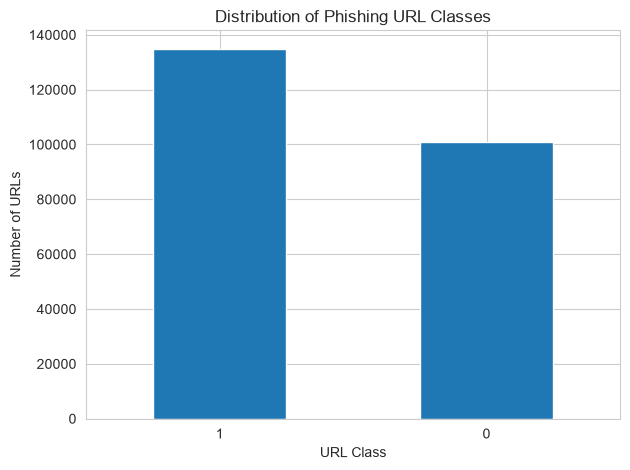

In [31]:

# 2.2 Identify the phishing target column
target_candidates = [
    'label', 'Label', 'status', 'Status',
    'result', 'Result', 'class', 'Class',
    'phishing', 'Phishing', 'is_phishing',
    'is_phishing_url', 'legitimate'
]

phishing_target = next(
    (col for col in target_candidates if col in df_phishing.columns),
    None
)

if phishing_target is not None:
    print("Target column:", phishing_target)
    print("\nClass counts:")
    print(df_phishing[phishing_target].value_counts(dropna=False))

    print("\nClass percentages:")
    print(
        (df_phishing[phishing_target].value_counts(normalize=True) * 100)
        .round(2)
    )

    df_phishing[phishing_target].value_counts().plot(
        kind='bar',
        xlabel='URL Class',
        ylabel='Number of URLs',
        title='Distribution of Phishing URL Classes',
        rot=0
    )
    plt.tight_layout()
    plt.show()
else:
    print("Target column not identified automatically.")
    print("Review the column names printed in Section 3.1.")


#### **2.3 Exploring numerical URL characteristics**
This helps in understanding the numerical features available for detecting suspicious URLs.

Numerical columns: 51


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


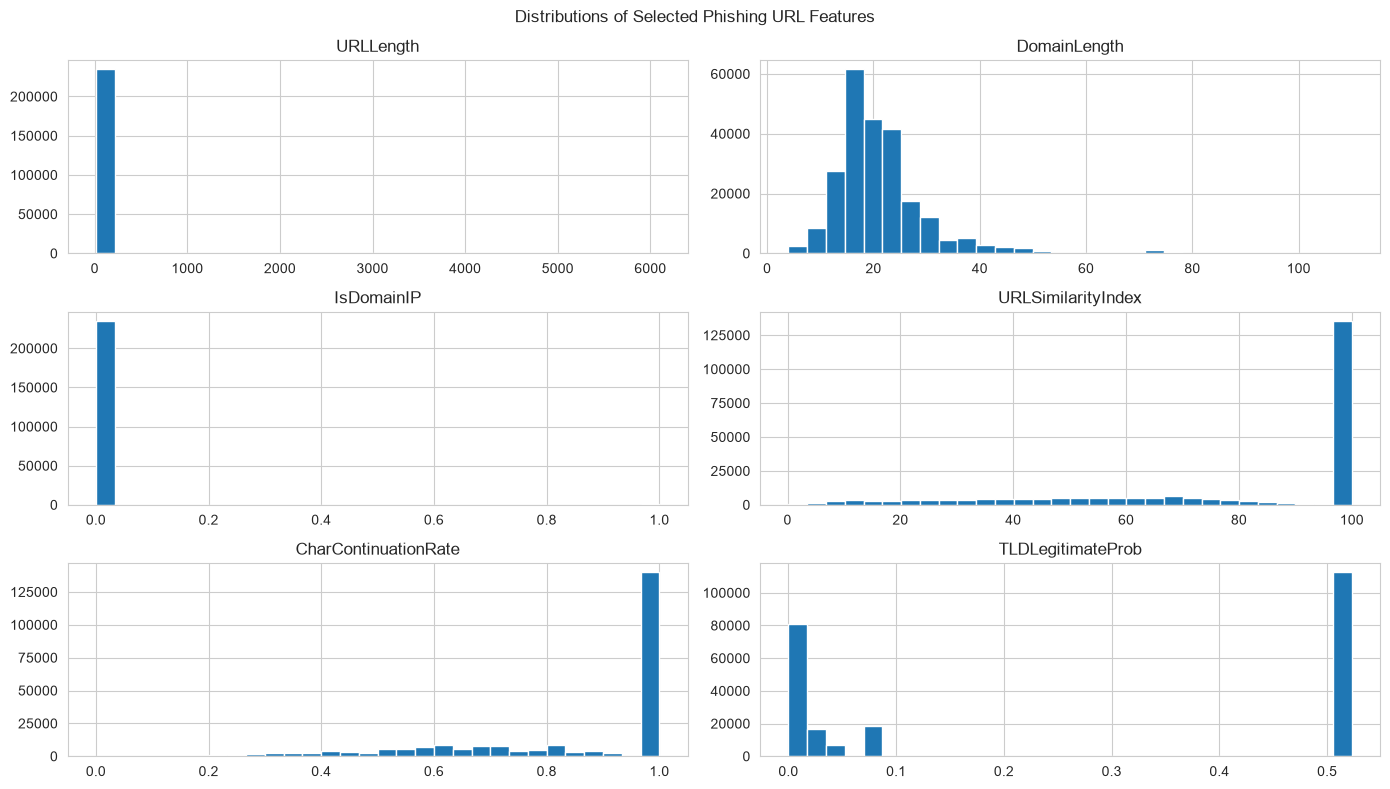

In [ ]:

# 2.3 Explore numerical features in the phishing dataset
phishing_numeric = df_phishing.select_dtypes(include=np.number)

print("Numerical columns:", phishing_numeric.shape[1])

display(phishing_numeric.describe().T)

# Plot up to six numerical feature distributions
selected_features = phishing_numeric.columns[:6]

if len(selected_features) > 0:
    phishing_numeric[selected_features].hist(
        figsize=(14, 8),
        bins=30
    )
    plt.suptitle('Distributions of Selected Phishing URL Features')
    plt.tight_layout()
    plt.show()


### **3.EDA for the Fake Job Postings dataset**
For this section, we used df_fake_jobs_clean so that the analysis reflects our cleaned copy rather than changing the original dataset. 

#### **3.1 Analyze legitimate versus fraudulent jobs**

Dataset shape: (17879, 18)

Fraud counts:
fraudulent
0    17014
1      865
Name: count, dtype: int64

Fraud percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


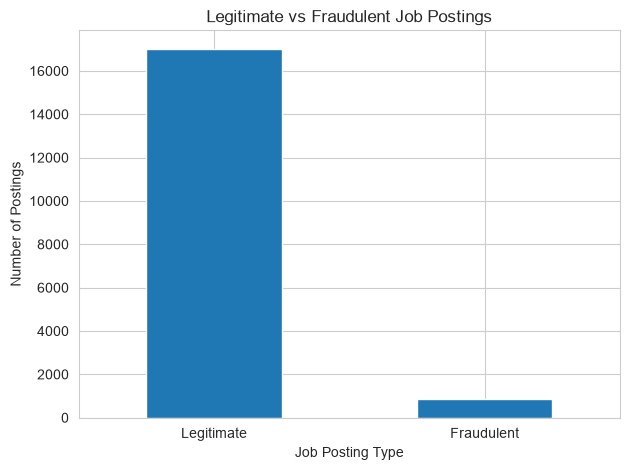

In [33]:

# 3.1 Distribution of fraudulent and legitimate job postings
print("Dataset shape:", df_fake_jobs_clean.shape)

fraud_counts = df_fake_jobs_clean['fraudulent'].value_counts().sort_index()

print("\nFraud counts:")
print(fraud_counts)

print("\nFraud percentages:")
print(
    (df_fake_jobs_clean['fraudulent'].value_counts(normalize=True) * 100)
    .round(2)
)

fraud_counts.rename({
    0: 'Legitimate',
    1: 'Fraudulent'
}).plot(
    kind='bar',
    xlabel='Job Posting Type',
    ylabel='Number of Postings',
    title='Legitimate vs Fraudulent Job Postings',
    rot=0
)

plt.tight_layout()
plt.show()


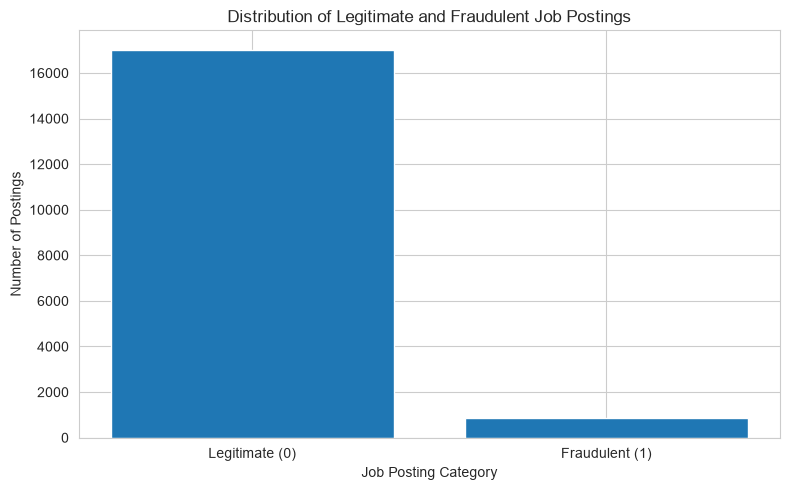

In [47]:
fraud_counts = df_fake_jobs["fraudulent"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    ["Legitimate (0)", "Fraudulent (1)"],
    fraud_counts.values
)

plt.title("Distribution of Legitimate and Fraudulent Job Postings")
plt.xlabel("Job Posting Category")
plt.ylabel("Number of Postings")
plt.tight_layout()
plt.show()


#### **3.2 Explore job categories**
We will examinened employment type, industry and education requirements to see which categories appear most often.


Top categories in employment_type:


employment_type
Full-time    11620
Unknown       3470
Contract      1524
Part-time      797
Temporary      241
Other          227
Name: count, dtype: int64

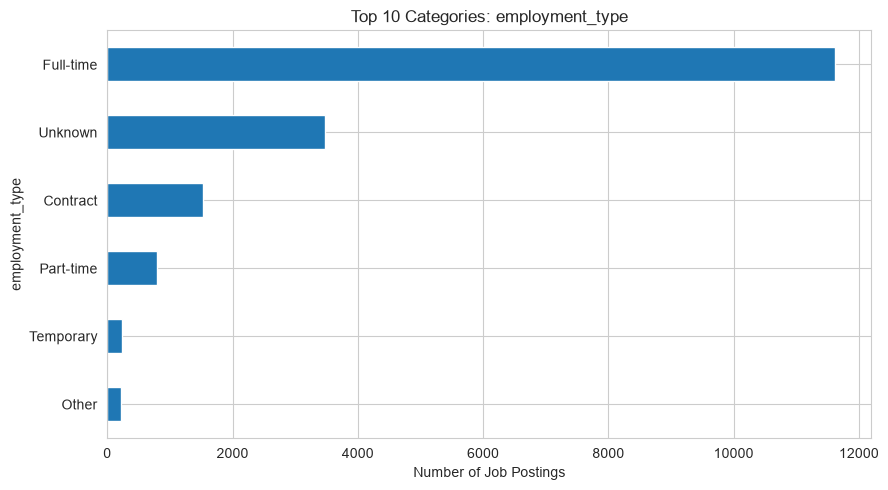


Top categories in industry:


industry
Unknown                                4902
Information Technology and Services    1734
Computer Software                      1376
Internet                               1062
Marketing and Advertising               828
Education Management                    822
Financial Services                      779
Hospital & Health Care                  497
Consumer Services                       358
Telecommunications                      342
Name: count, dtype: int64

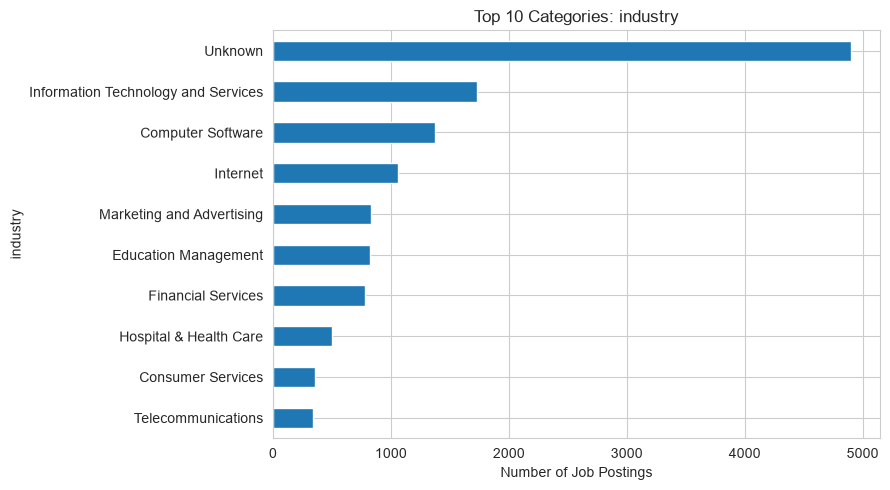


Top categories in required_education:


required_education
Unknown                              8104
Bachelor's Degree                    5145
High School or equivalent            2080
Unspecified                          1397
Master's Degree                       416
Associate Degree                      274
Certification                         170
Some College Coursework Completed     102
Professional                           74
Vocational                             49
Name: count, dtype: int64

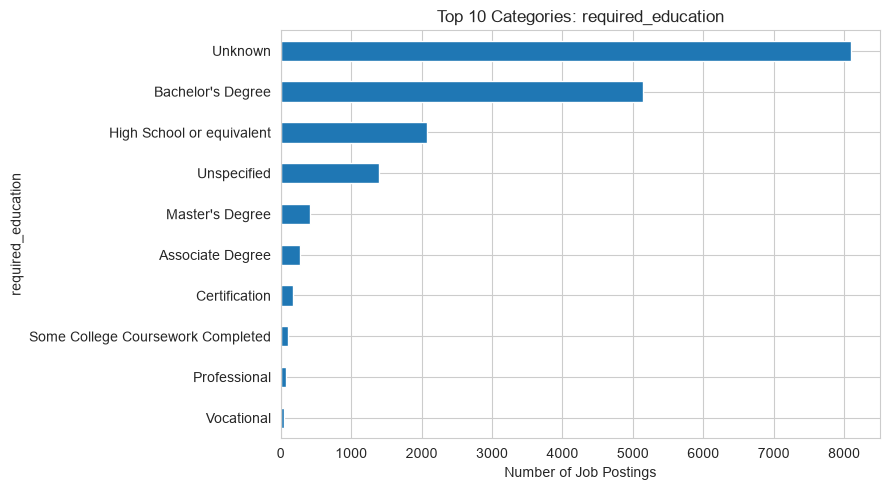

In [34]:

# 3.2 Explore categorical features
job_categories = [
    'employment_type',
    'industry',
    'required_education'
]

for column in job_categories:
    if column in df_fake_jobs_clean.columns:
        print(f'\nTop categories in {column}:')

        counts = (
            df_fake_jobs_clean[column]
            .fillna('Unknown')
            .replace('', 'Not Provided')
            .value_counts()
            .head(10)
        )

        display(counts)

        counts.sort_values().plot(
            kind='barh',
            figsize=(9, 5),
            title=f'Top 10 Categories: {column}',
            xlabel='Number of Job Postings'
        )

        plt.tight_layout()
        plt.show()


### **3.3 Comparing job descriptions by fraud status**
This investigates whether fraudulent and legitimate job postings differ in description length.

,count,mean,std,min,25%,50%,75%,max
fraudulent,,,,,,,,
0,17014.0,1221.219701,889.139777,6.0,616.0,1027.0,1589.0,14907.0
1,865.0,1156.169942,998.329255,9.0,467.0,846.0,1541.0,8578.0


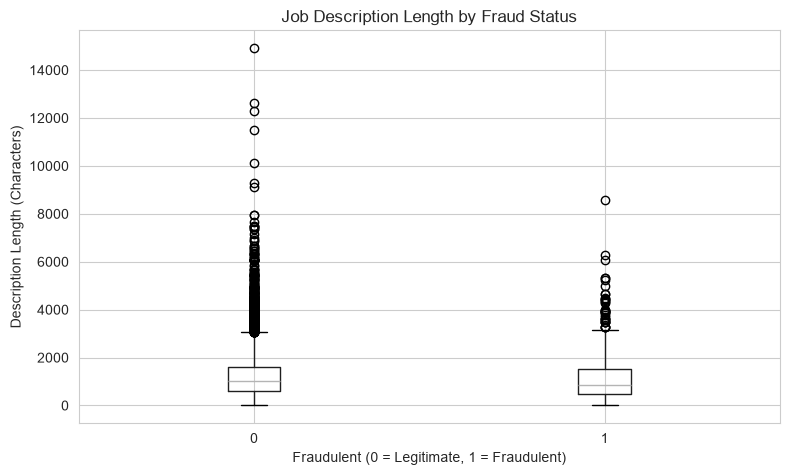

In [35]:

# 3.3 Analyze job description length
df_fake_jobs_clean['description_length'] = (
    df_fake_jobs_clean['description'].fillna('').str.len()
)

display(
    df_fake_jobs_clean.groupby('fraudulent')['description_length']
    .describe()
)

df_fake_jobs_clean.boxplot(
    column='description_length',
    by='fraudulent',
    figsize=(8, 5)
)

plt.title('Job Description Length by Fraud Status')
plt.suptitle('')
plt.xlabel('Fraudulent (0 = Legitimate, 1 = Fraudulent)')
plt.ylabel('Description Length (Characters)')
plt.tight_layout()
plt.show()


### **4. EDA for the SMS Spam Collection**
The SMS dataset contains two main fields: label and message. We will examine spam prevalence, message length and frequent words.

#### **4.1 Analyzing spam versus legitimate messages**

Dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


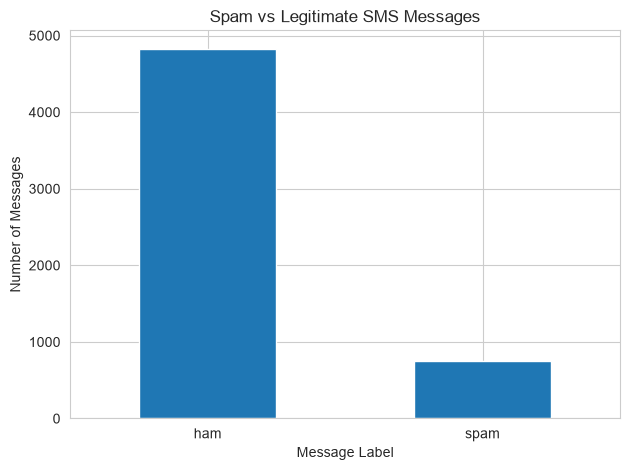

In [36]:

# 4.1 Distribution of SMS labels
print("Dataset shape:", df_sms.shape)

print("\nLabel counts:")
print(df_sms['label'].value_counts())

print("\nLabel percentages:")
print((df_sms['label'].value_counts(normalize=True) * 100).round(2))

df_sms['label'].value_counts().plot(
    kind='bar',
    xlabel='Message Label',
    ylabel='Number of Messages',
    title='Spam vs Legitimate SMS Messages',
    rot=0
)

plt.tight_layout()
plt.show()


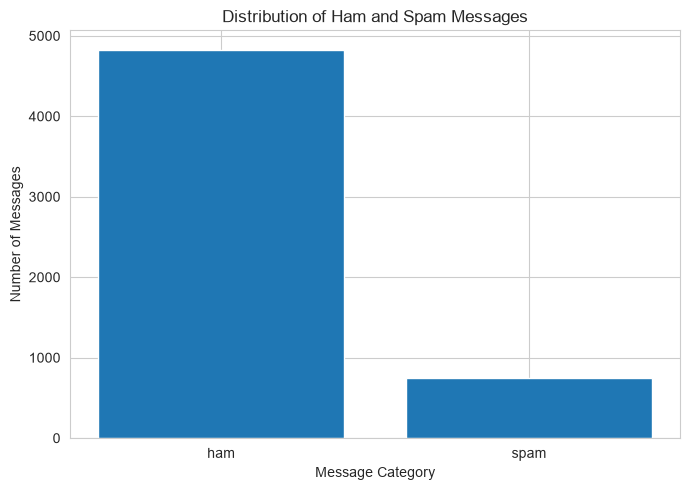

In [48]:
# Visualizing the label distribution
label_counts = df_sms["label"].value_counts().reindex(["ham", "spam"])

plt.figure(figsize=(7, 5))
plt.bar(label_counts.index, label_counts.values)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


Class imbalance: There are approximately 6.46 legitimate messages for every spam message.

#### **4.2 Examine message lengths**

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4825.0,71.482487,58.440652,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.670683,28.873603,13.0,133.0,149.0,157.0,223.0


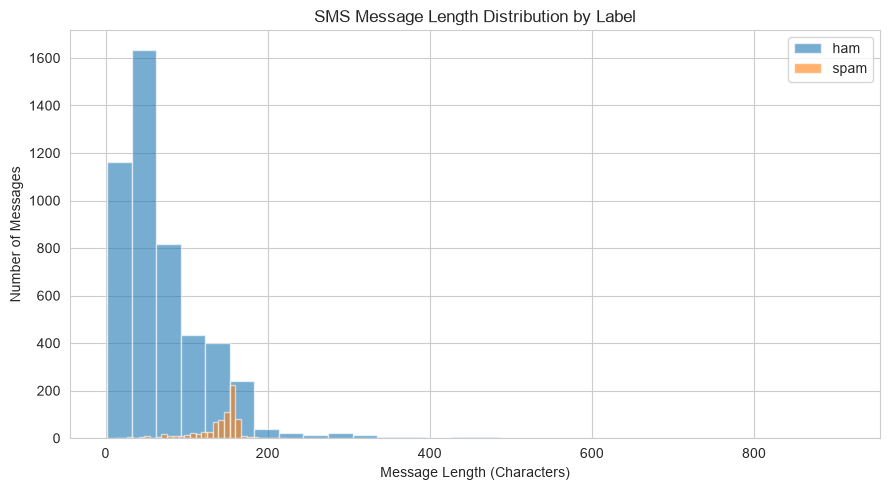

In [37]:

# 4.2 Calculate message lengths
df_sms['message_length'] = df_sms['message'].fillna('').str.len()

display(
    df_sms.groupby('label')['message_length'].describe()
)

for label in df_sms['label'].dropna().unique():
    df_sms.loc[
        df_sms['label'] == label, 'message_length'
    ].hist(
        bins=30,
        alpha=0.6,
        figsize=(9, 5),
        label=str(label)
    )

plt.title('SMS Message Length Distribution by Label')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Number of Messages')
plt.legend()
plt.tight_layout()
plt.show()


### **5. EDA for the Community Scam Reports dataset**
This dataset supports TrustShield's community intelligence feature. Its current records are synthetic, so  this analysis is to test the reporting workflow rather than draw conclusions about real scam prevalence.

### **5.1 Explore report categories and platforms**

Dataset shape: (10, 10)

Report types:
report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64

Platforms:
platform
SMS         3
WhatsApp    2
TikTok      2
Website     2
Email       1
Name: count, dtype: int64


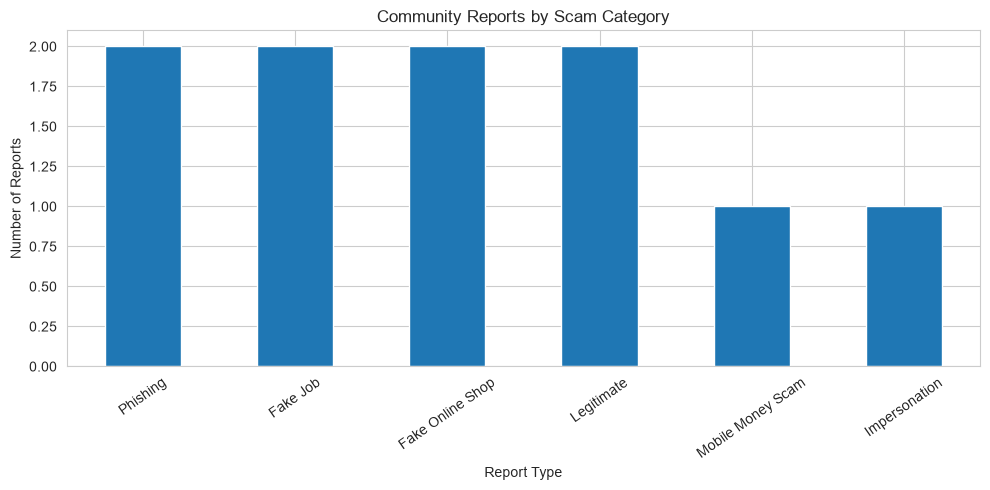

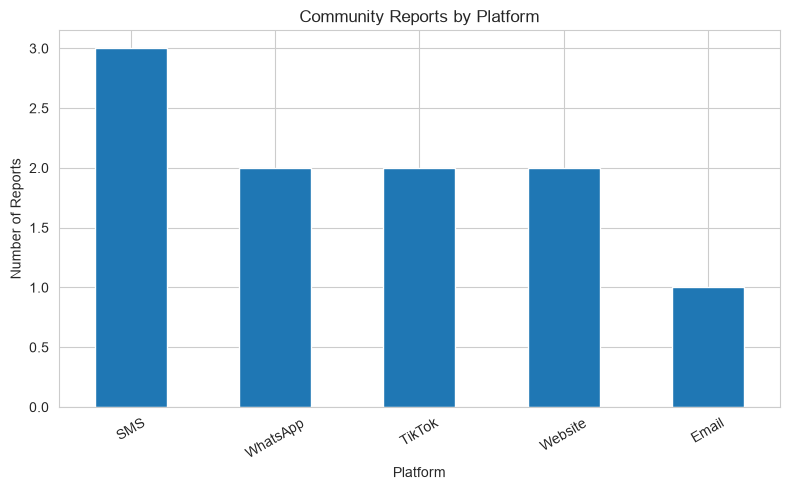

In [38]:

# 5.1 Exploring community report categories
print("Dataset shape:", df_community.shape)

print("\nReport types:")
print(df_community['report_type'].value_counts())

print("\nPlatforms:")
print(df_community['platform'].value_counts())

# Plot report types
df_community['report_type'].value_counts().plot(
    kind='bar',
    figsize=(10, 5),
    xlabel='Report Type',
    ylabel='Number of Reports',
    title='Community Reports by Scam Category',
    rot=35
)

plt.tight_layout()
plt.show()

# Plot reporting platforms
df_community['platform'].value_counts().plot(
    kind='bar',
    figsize=(8, 5),
    xlabel='Platform',
    ylabel='Number of Reports',
    title='Community Reports by Platform',
    rot=30
)

plt.tight_layout()
plt.show()


#### **5.2 Examining suspicious versus legitimate reports**

Suspiciousness counts:
is_suspicious
1    8
0    2
Name: count, dtype: int64

Suspiciousness percentages:
is_suspicious
1    80.0
0    20.0
Name: proportion, dtype: float64


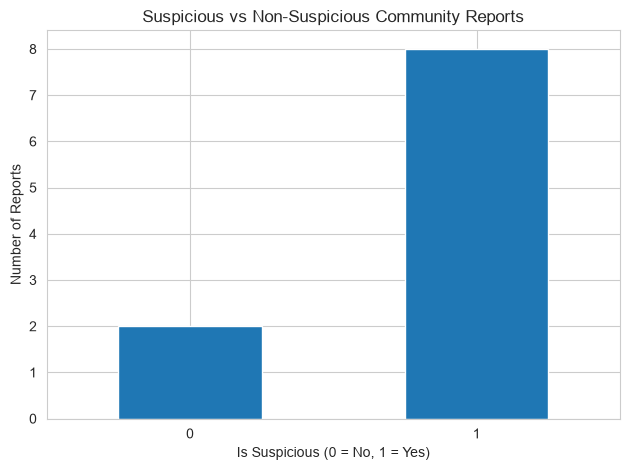


Verification status:
verification_status
Unverified    10
Name: count, dtype: int64


In [39]:

# 5.2 Analyzing the suspiciousness label
print("Suspiciousness counts:")
print(df_community['is_suspicious'].value_counts(dropna=False))

print("\nSuspiciousness percentages:")
print(
    (df_community['is_suspicious'].value_counts(normalize=True) * 100)
    .round(2)
)

df_community['is_suspicious'].value_counts().sort_index().plot(
    kind='bar',
    xlabel='Is Suspicious (0 = No, 1 = Yes)',
    ylabel='Number of Reports',
    title='Suspicious vs Non-Suspicious Community Reports',
    rot=0
)

plt.tight_layout()
plt.show()

print("\nVerification status:")
print(df_community['verification_status'].value_counts(dropna=False))


#### **5.3 Identifying repeated URLs, phone identifiers and sellers**
Repeated identifiers can help reveal patterns that deserve further review.

In [40]:

# 5.3 Finding repeated community indicators
indicators = [
    'suspicious_url',
    'phone_number',
    'seller_id'
]

for column in indicators:
    if column in df_community.columns:
        values = df_community[column].fillna('').astype(str).str.strip()

        # Exclude placeholders and empty values
        values = values[
            ~values.str.lower().isin(['', 'n/a', 'unknown', 'nan'])
        ]

        repeated = values.value_counts()
        repeated = repeated[repeated > 1]

        print(f'\nRepeated values in {column}:')

        if repeated.empty:
            print("No repeated identifiers found.")
        else:
            display(repeated)



Repeated values in suspicious_url:


suspicious_url
http://login.example.com    2
http://jobs.example.org     2
http://shop.example.net     2
Name: count, dtype: int64


Repeated values in phone_number:


phone_number
SYNTHETIC_PHONE_002    2
SYNTHETIC_PHONE_003    2
Name: count, dtype: int64


Repeated values in seller_id:


seller_id
SELLER_SYN_001    2
Name: count, dtype: int64

#### **5.4 Examine reports over time**

Reports per date:


report_date
2026-10-01    1
2026-10-02    1
2026-10-03    1
2026-10-04    1
2026-10-05    1
2026-10-06    1
2026-10-07    1
2026-10-08    1
2026-10-09    1
2026-10-10    1
dtype: int64

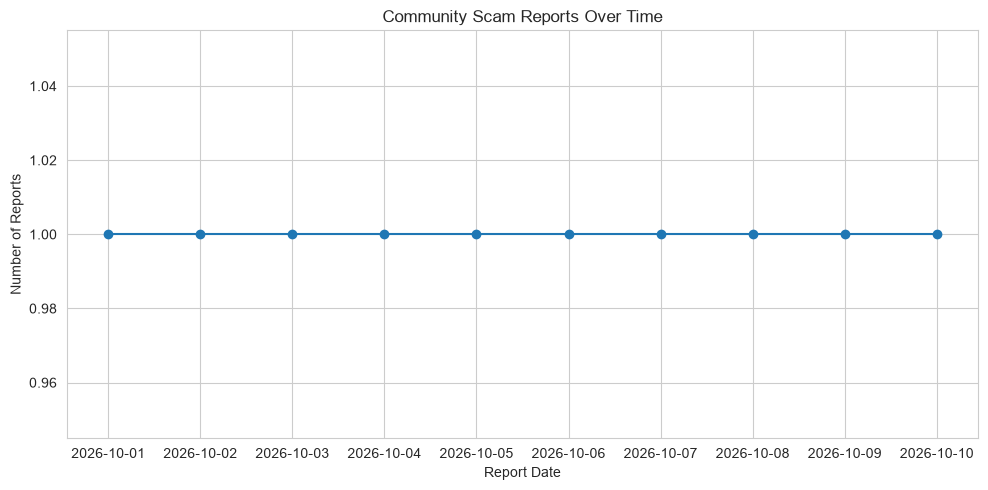

In [41]:

# 5.4 Explore reports by date
df_community['report_date'] = pd.to_datetime(
    df_community['report_date'],
    errors='coerce'
)

reports_over_time = (
    df_community.dropna(subset=['report_date'])
    .groupby(df_community['report_date'].dt.date)
    .size()
)

print("Reports per date:")
display(reports_over_time)

reports_over_time.plot(
    figsize=(10, 5),
    marker='o',
    xlabel='Report Date',
    ylabel='Number of Reports',
    title='Community Scam Reports Over Time'
)

plt.tight_layout()
plt.show()


### **6.Summary of EDA Findings**

In [42]:

# 6. EDA Summary

print("=" * 60)
print("TRUSTSHIELD 254 - EDA SUMMARY")
print("=" * 60)

print("\n1. PHISHING URL DATASET")
print("Rows and columns:", df_phishing.shape)
print("Potential target column:", phishing_target)

print("\n2. FAKE JOB POSTINGS DATASET")
print("Rows and columns:", df_fake_jobs_clean.shape)
print("Fraud distribution:")
print(df_fake_jobs_clean['fraudulent'].value_counts())

print("\n3. SMS SPAM COLLECTION")
print("Rows and columns:", df_sms.shape)
print("Message distribution:")
print(df_sms['label'].value_counts())

print("\n4. COMMUNITY SCAM REPORTS")
print("Rows and columns:", df_community.shape)
print("Report categories:")
print(df_community['report_type'].value_counts())
print("Repeated indicators will require further investigation.")

print("\nEDA overview completed.")


TRUSTSHIELD 254 - EDA SUMMARY

1. PHISHING URL DATASET
Rows and columns: (235795, 56)
Potential target column: label

2. FAKE JOB POSTINGS DATASET
Rows and columns: (17879, 19)
Fraud distribution:
fraudulent
0    17014
1      865
Name: count, dtype: int64

3. SMS SPAM COLLECTION
Rows and columns: (5572, 3)
Message distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

4. COMMUNITY SCAM REPORTS
Rows and columns: (10, 10)
Report categories:
report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64
Repeated indicators will require further investigation.

EDA overview completed.


## **Sumary of the Datasets**

#### **Phishing URL Dataset**
235,795 rows · 56 columns
Large dataset with a target column identified as label. Next, inspecting the label values and feature types.




#### **Fake Job Postings**
17,879 rows · 19 columns
17,014 legitimate and 865 fraudulent postings.
Fraudulent: 4.84% · Legitimate: 95.16%

#### **SMS Spam Collection**
5,572 rows · 3 columns
4,825 legitimate messages and 747 spam messages.
Spam: 13.41% · Legitimate: 86.59%

#### **Community Scam Reports**
10 synthetic reports
Suitable for testing report categories, repeated indicators and reporting workflows, but not for drawing conclusions about real-world scam trends.

#### **Important EDA findings: class imbalance**
Your fake job and SMS datasets are imbalanced. Fraudulent job postings make up only 4.84% of the job dataset, while spam makes up 13.41% of SMS messages.

This matters because a model could appear accurate simply by predicting the majority class. For example, a model that predicts every job is legitimate would achieve about 95.16% accuracy on your job dataset while detecting zero fraudulent jobs.

During modelling, we'll therefore pay close attention to fraud-class recall, precision, F1-score and the confusion matrix, rather than relying on accuracy alone.

In [43]:

# Inspecting phishing URL target labels
print("Target column: label")

print("\nLabel counts:")
display(df_phishing['label'].value_counts(dropna=False))

print("\nLabel percentages:")
display(
    (df_phishing['label'].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\nData types:")
display(df_phishing.dtypes.value_counts())

print("\nFirst five rows:")
display(df_phishing.head())


Target column: label

Label counts:


label
1    134850
0    100945
Name: count, dtype: int64


Label percentages:


label
1    57.19
0    42.81
Name: proportion, dtype: float64


Data types:


int64      41
float64    10
str         5
Name: count, dtype: int64


First five rows:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [44]:

# Inspecting community scam reports
print("Dataset shape:", df_community.shape)

print("\nReport categories:")
display(df_community['report_type'].value_counts())

print("\nSuspicious vs legitimate reports:")
display(df_community['is_suspicious'].value_counts())

print("\nRepeated URLs:")
display(
    df_community['suspicious_url']
    .value_counts()
    .loc[lambda x: x.index != 'N/A']
    .loc[lambda x: x > 1]
)

print("\nRepeated seller identifiers:")
display(
    df_community['seller_id']
    .value_counts()
    .loc[lambda x: x.index != 'N/A']
    .loc[lambda x: x > 1]
)


Dataset shape: (10, 10)

Report categories:


report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64


Suspicious vs legitimate reports:


is_suspicious
1    8
0    2
Name: count, dtype: int64


Repeated URLs:


suspicious_url
http://login.example.com    2
http://jobs.example.org     2
http://shop.example.net     2
Name: count, dtype: int64


Repeated seller identifiers:


seller_id
SELLER_SYN_001    2
Name: count, dtype: int64

In [45]:

# Inspecting label values and examples
print("Unique labels:")
print(sorted(df_phishing['label'].dropna().unique()))

print("\nExamples for label 0:")
display(
    df_phishing.loc[
        df_phishing['label'] == 0,
        ['URL', 'Domain', 'label']
    ].head(10)
)

print("\nExamples for label 1:")
display(
    df_phishing.loc[
        df_phishing['label'] == 1,
        ['URL', 'Domain', 'label']
    ].head(10)
)


Unique labels:
[np.int64(0), np.int64(1)]

Examples for label 0:


,URL,Domain,label
11,http://www.teramill.com,www.teramill.com,0
20,http://www.f0519141.xsph.ru,www.f0519141.xsph.ru,0
21,http://www.shprakserf.gq,www.shprakserf.gq,0
27,https://service-mitld.firebaseapp.com/,service-mitld.firebaseapp.com,0
28,http://www.kuradox92.lima-city.de,www.kuradox92.lima-city.de,0
29,https://liuy-9a930.web.app/,liuy-9a930.web.app,0
31,https://ipfs.io/ipfs/qmrvvyr84esa2assw9vvwupqj...,ipfs.io,0
32,http://att-103731-107123.weeblysite.com/,att-103731-107123.weeblysite.com,0
34,https://hidok4f8zl.firebaseapp.com/,hidok4f8zl.firebaseapp.com,0
37,http://www.ooguy.com,www.ooguy.com,0



Examples for label 1:


,URL,Domain,label
0,https://www.southbankmosaics.com,www.southbankmosaics.com,1
1,https://www.uni-mainz.de,www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,www.rewildingargentina.org,1
5,https://www.globalreporting.org,www.globalreporting.org,1
6,https://www.saffronart.com,www.saffronart.com,1
7,https://www.nerdscandy.com,www.nerdscandy.com,1
8,https://www.hyderabadonline.in,www.hyderabadonline.in,1
9,https://www.aap.org,www.aap.org,1


# **4. DATA PREPROCESSING**
preparing data for machine learning

Data preprocessing includes cleaning, but also prepares the cleaned data for a model. This involves:
- Separating features from the target
- Splitting data into training and testing sets
- Converting text into numerical features
- Encoding categorical variables
- Scaling numerical features when necessary
- Handling class imbalance
- Preventing data leakage
Goal: Make the data suitable for training and evaluating a model.

### **1.Inspecting the datasets before preprocessing**

In [51]:

datasets = {
    "Phishing URLs": df_phishing,
    "Fake Job Postings": df_fake_jobs_clean,
    "SMS Spam": df_sms,
    "Community Scam Reports": df_community
}

for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print("Shape:", df.shape)

    print("\nColumns and data types:")
    print(df.dtypes)

    print("\nMissing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    print("\nFirst 3 rows:")
    print(df.head(3))



PHISHING URLS
Shape: (235795, 56)

Columns and data types:
FILENAME                          str
URL                               str
URLLength                       int64
Domain                            str
DomainLength                    int64
IsDomainIP                      int64
TLD                               str
URLSimilarityIndex            float64
CharContinuationRate          float64
TLDLegitimateProb             float64
URLCharProb                   float64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL       

### **2. Preparing the fake-job features**
The goal here is to organize columns into text, categorical, and numerical groups. We won't vectorize or encode them yet; those transformations should be fitted after the train/test split.

In [ ]:
# Working with the cleaned dataset without modifying it
df_jobs = df_fake_jobs_clean.copy()

# Separating the target
target_column = "fraudulent"

X_jobs = df_jobs.drop(columns=[target_column])
y_jobs = df_jobs[target_column].copy()

# Removing the job ID from the predictive features
X_jobs = X_jobs.drop(columns=["job_id"], errors="ignore")

# Identifying text columns
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

text_columns = [
    col for col in text_columns
    if col in X_jobs.columns
]

# Identifying categorical columns
categorical_columns = X_jobs.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Removing text columns from the categorical list
categorical_columns = [
    col for col in categorical_columns
    if col not in text_columns
]

# Identifying numerical columns
numerical_columns = X_jobs.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

# Displaying the feature groups
print("TEXT COLUMNS:")
print(text_columns)

print("\nCATEGORICAL COLUMNS:")
print(categorical_columns)

print("\nNUMERICAL COLUMNS:")
print(numerical_columns)

print("\nFeatures shape:", X_jobs.shape)
print("Target shape:", y_jobs.shape)

print("\nTarget values:")
print(y_jobs.value_counts().sort_index())


TEXT COLUMNS:
['title', 'company_profile', 'description', 'requirements', 'benefits']

CATEGORICAL COLUMNS:
['location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']

NUMERICAL COLUMNS:
['telecommuting', 'has_company_logo', 'has_questions', 'description_length']

Features shape: (17879, 17)
Target shape: (17879,)

Target values:
fraudulent
0    17014
1      865
Name: count, dtype: int64


### **3.Preparing the text features**
For the fake-job dataset, the five text columns can contain useful fraud indicators. Rather than vectorizing each column separately, we will combine them into one text feature for an initial model.

In [53]:
# Creating a separate modelling copy
df_jobs_model = df_fake_jobs_clean.copy()

# Combining the five text columns into one feature
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

df_jobs_model["combined_text"] = (
    df_jobs_model[text_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
)

# Removing the original text columns and job identifier
df_jobs_model = df_jobs_model.drop(
    columns=text_columns + ["job_id"],
    errors="ignore"
)

# Separating features and target
X_jobs = df_jobs_model.drop(columns=["fraudulent"])
y_jobs = df_jobs_model["fraudulent"].copy()

# Inspecting the result
print("Modelling dataset shape:", df_jobs_model.shape)

print("\nRemaining columns:")
print(df_jobs_model.columns.tolist())

print("\nSample combined text:")
print(df_jobs_model["combined_text"].iloc[0][:500])

print("\nTarget distribution:")
print(y_jobs.value_counts())


Modelling dataset shape: (17879, 14)

Remaining columns:
['location', 'department', 'salary_range', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent', 'description_length', 'combined_text']

Sample combined text:
Marketing Intern We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to connect people around their specific food interests, and to offer them superb, highly curated information about food and cooking. We attract the most talented home cooks and contributor

Target distribution:
fraudulent
0    17014
1      865
Name: count, dtype: int64


### **4. Checking the prepared features**

In [54]:

# Separating target and features
X_jobs = df_jobs_model.drop(columns=["fraudulent"])
y_jobs = df_jobs_model["fraudulent"]

# Defining feature groups
text_columns = ["combined_text"]

categorical_columns = [
    "location",
    "department",
    "salary_range",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

numerical_columns = [
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "description_length"
]

# Confirming columns exist
print("All text columns exist:",
      all(c in X_jobs.columns for c in text_columns))

print("All categorical columns exist:",
      all(c in X_jobs.columns for c in categorical_columns))

print("All numerical columns exist:",
      all(c in X_jobs.columns for c in numerical_columns))

print("\nMissing values in X_jobs:", X_jobs.isnull().sum().sum())
print("Missing values in y_jobs:", y_jobs.isnull().sum())

print("\nFeatures shape:", X_jobs.shape)
print("Target shape:", y_jobs.shape)


All text columns exist: True
All categorical columns exist: True
All numerical columns exist: True

Missing values in X_jobs: 0
Missing values in y_jobs: 0

Features shape: (17879, 13)
Target shape: (17879,)


### **5. Preparing the phishing URL dataset**

In [55]:

print("Dataset shape:", df_phishing.shape)

print("\nAll column names:")
for column in df_phishing.columns:
    print(column)

print("\nData types:")
print(df_phishing.dtypes.to_string())

print("\nTarget distribution:")
print(df_phishing["label"].value_counts(dropna=False))

print("\nExamples of URL and label:")
print(
    df_phishing[["URL", "Domain", "label"]]
    .head(10)
    .to_string(index=False)
)


Dataset shape: (235795, 56)

All column names:
FILENAME
URL
URLLength
Domain
DomainLength
IsDomainIP
TLD
URLSimilarityIndex
CharContinuationRate
TLDLegitimateProb
URLCharProb
TLDLength
NoOfSubDomain
HasObfuscation
NoOfObfuscatedChar
ObfuscationRatio
NoOfLettersInURL
LetterRatioInURL
NoOfDegitsInURL
DegitRatioInURL
NoOfEqualsInURL
NoOfQMarkInURL
NoOfAmpersandInURL
NoOfOtherSpecialCharsInURL
SpacialCharRatioInURL
IsHTTPS
LineOfCode
LargestLineLength
HasTitle
Title
DomainTitleMatchScore
URLTitleMatchScore
HasFavicon
Robots
IsResponsive
NoOfURLRedirect
NoOfSelfRedirect
HasDescription
NoOfPopup
NoOfiFrame
HasExternalFormSubmit
HasSocialNet
HasSubmitButton
HasHiddenFields
HasPasswordField
Bank
Pay
Crypto
HasCopyrightInfo
NoOfImage
NoOfCSS
NoOfJS
NoOfSelfRef
NoOfEmptyRef
NoOfExternalRef
label

Data types:
FILENAME                          str
URL                               str
URLLength                       int64
Domain                            str
DomainLength                    int64


### **6.Inspecting the complete columns and label distribution**

In [56]:
# Displaying every column with its index
for i, column in enumerate(df_phishing.columns):
    print(f"{i + 1:02d}. {column} — {df_phishing[column].dtype}")

print("\nTarget label counts:")
print(df_phishing["label"].value_counts(dropna=False).sort_index())

print("\nTarget label percentages:")
print(
    (df_phishing["label"].value_counts(normalize=True, dropna=False)
     .sort_index() * 100).round(2)
)

print("\nMissing target values:", df_phishing["label"].isna().sum())


01. FILENAME — str
02. URL — str
03. URLLength — int64
04. Domain — str
05. DomainLength — int64
06. IsDomainIP — int64
07. TLD — str
08. URLSimilarityIndex — float64
09. CharContinuationRate — float64
10. TLDLegitimateProb — float64
11. URLCharProb — float64
12. TLDLength — int64
13. NoOfSubDomain — int64
14. HasObfuscation — int64
15. NoOfObfuscatedChar — int64
16. ObfuscationRatio — float64
17. NoOfLettersInURL — int64
18. LetterRatioInURL — float64
19. NoOfDegitsInURL — int64
20. DegitRatioInURL — float64
21. NoOfEqualsInURL — int64
22. NoOfQMarkInURL — int64
23. NoOfAmpersandInURL — int64
24. NoOfOtherSpecialCharsInURL — int64
25. SpacialCharRatioInURL — float64
26. IsHTTPS — int64
27. LineOfCode — int64
28. LargestLineLength — int64
29. HasTitle — int64
30. Title — str
31. DomainTitleMatchScore — float64
32. URLTitleMatchScore — float64
33. HasFavicon — int64
34. Robots — int64
35. IsResponsive — int64
36. NoOfURLRedirect — int64
37. NoOfSelfRedirect — int64
38. HasDescription — 

In [57]:
# Inspecting the phishing dataset before preprocessing

print("Dataset shape:", df_phishing.shape)

print("\nAll columns:")
for i, column in enumerate(df_phishing.columns, start=1):
    print(f"{i:02d}. {column}")

print("\nMissing values:")
print("Total missing cells:", df_phishing.isnull().sum().sum())
print("Columns with missing values:")
print(df_phishing.isnull().sum()[df_phishing.isnull().sum() > 0])

print("\nDuplicate rows:", df_phishing.duplicated().sum())

print("\nTarget distribution:")
print(df_phishing["label"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (df_phishing["label"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nTarget meaning:")
print("0 = Phishing URL")
print("1 = Legitimate URL")

Dataset shape: (235795, 56)

All columns:
01. FILENAME
02. URL
03. URLLength
04. Domain
05. DomainLength
06. IsDomainIP
07. TLD
08. URLSimilarityIndex
09. CharContinuationRate
10. TLDLegitimateProb
11. URLCharProb
12. TLDLength
13. NoOfSubDomain
14. HasObfuscation
15. NoOfObfuscatedChar
16. ObfuscationRatio
17. NoOfLettersInURL
18. LetterRatioInURL
19. NoOfDegitsInURL
20. DegitRatioInURL
21. NoOfEqualsInURL
22. NoOfQMarkInURL
23. NoOfAmpersandInURL
24. NoOfOtherSpecialCharsInURL
25. SpacialCharRatioInURL
26. IsHTTPS
27. LineOfCode
28. LargestLineLength
29. HasTitle
30. Title
31. DomainTitleMatchScore
32. URLTitleMatchScore
33. HasFavicon
34. Robots
35. IsResponsive
36. NoOfURLRedirect
37. NoOfSelfRedirect
38. HasDescription
39. NoOfPopup
40. NoOfiFrame
41. HasExternalFormSubmit
42. HasSocialNet
43. HasSubmitButton
44. HasHiddenFields
45. HasPasswordField
46. Bank
47. Pay
48. Crypto
49. HasCopyrightInfo
50. NoOfImage
51. NoOfCSS
52. NoOfJS
53. NoOfSelfRef
54. NoOfEmptyRef
55. NoOfExtern

In [58]:
# Creating a separate modeling copy
df_phishing_model = df_phishing.copy()

# Removing the filename identifier
df_phishing_model = df_phishing_model.drop(
    columns=["FILENAME"],
    errors="ignore"
)

# Separating features and target
X_phishing = df_phishing_model.drop(columns=["label"])
y_phishing = df_phishing_model["label"].copy()

# Displaying the results
print("Feature matrix shape:", X_phishing.shape)
print("Target shape:", y_phishing.shape)

print("\nFeature data types:")
print(X_phishing.dtypes.value_counts())

print("\nMissing values in features:", X_phishing.isnull().sum().sum())
print("Missing values in target:", y_phishing.isnull().sum())

print("\nTarget counts:")
print(y_phishing.value_counts().sort_index())

Feature matrix shape: (235795, 54)
Target shape: (235795,)

Feature data types:
int64      40
float64    10
str         4
Name: count, dtype: int64

Missing values in features: 0
Missing values in target: 0

Target counts:
label
0    100945
1    134850
Name: count, dtype: int64


In [59]:
# Identifying text/categorical columns
text_columns_phishing = X_phishing.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Identifying numeric columns
numerical_columns_phishing = X_phishing.select_dtypes(
    include=["number"]
).columns.tolist()

print("Text/categorical columns:")
print(text_columns_phishing)

print("\nNumber of numeric columns:", len(numerical_columns_phishing))

print("\nUnique values in text/categorical columns:")
for column in text_columns_phishing:
    print(f"{column}: {X_phishing[column].nunique()} unique values")

# Checking numeric columns for infinite values
import numpy as np

numeric_data = X_phishing[numerical_columns_phishing]

print(
    "\nTotal infinite numeric values:",
    np.isinf(numeric_data).sum().sum()
)

Text/categorical columns:
['URL', 'Domain', 'TLD', 'Title']

Number of numeric columns: 50

Unique values in text/categorical columns:
URL: 235370 unique values
Domain: 220086 unique values
TLD: 695 unique values
Title: 197874 unique values

Total infinite numeric values: 0


In [60]:
# Preparing the numeric features for the initial phishing model

X_phishing_numeric = X_phishing.select_dtypes(
    include=["number"]
).copy()

# Keeping the target unchanged
y_phishing = df_phishing["label"].copy()

print("Numeric feature matrix:", X_phishing_numeric.shape)
print("Target shape:", y_phishing.shape)

print("\nMissing feature values:",
      X_phishing_numeric.isnull().sum().sum())

print("Infinite feature values:",
      np.isinf(X_phishing_numeric).sum().sum())

print("\nDuplicate rows in numeric features:",
      X_phishing_numeric.duplicated().sum())

print("\nTarget distribution:")
print(y_phishing.value_counts().sort_index())

Numeric feature matrix: (235795, 50)
Target shape: (235795,)

Missing feature values: 0
Infinite feature values: 0

Duplicate rows in numeric features: 808

Target distribution:
label
0    100945
1    134850
Name: count, dtype: int64


In [61]:
# Checking whether identical numeric features have conflicting labels

duplicate_feature_rows = X_phishing_numeric.duplicated(keep=False)

duplicate_check = X_phishing_numeric.loc[
    duplicate_feature_rows
].copy()

duplicate_check["label"] = y_phishing.loc[
    duplicate_feature_rows
].values

print("Rows involved in repeated numeric feature patterns:",
      duplicate_feature_rows.sum())

print("\nLabel counts among these rows:")
print(duplicate_check["label"].value_counts().sort_index())

print("\nNumber of unique labels per repeated feature pattern:")
label_counts_per_pattern = (
    duplicate_check.groupby(list(X_phishing_numeric.columns))["label"]
    .nunique()
)

print(label_counts_per_pattern.value_counts().sort_index())

print("\nPatterns with conflicting labels:",
      (label_counts_per_pattern > 1).sum())

Rows involved in repeated numeric feature patterns: 1292

Label counts among these rows:
label
0    1292
Name: count, dtype: int64

Number of unique labels per repeated feature pattern:
label
1    484
Name: count, dtype: int64

Patterns with conflicting labels: 0


In [62]:
# Splitting the numeric features and target
X_phishing_train, X_phishing_test, y_phishing_train, y_phishing_test = (
    train_test_split(
        X_phishing_numeric,
        y_phishing,
        test_size=0.20,
        random_state=42,
        stratify=y_phishing
    )
)

# Checking the split sizes
print("Training feature shape:", X_phishing_train.shape)
print("Testing feature shape:", X_phishing_test.shape)

print("\nTraining target distribution:")
print(y_phishing_train.value_counts())
print(
    (y_phishing_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting target distribution:")
print(y_phishing_test.value_counts())
print(
    (y_phishing_test.value_counts(normalize=True) * 100).round(2)
)

Training feature shape: (188636, 50)
Testing feature shape: (47159, 50)

Training target distribution:
label
1    107880
0     80756
Name: count, dtype: int64
label
1    57.19
0    42.81
Name: proportion, dtype: float64

Testing target distribution:
label
1    26970
0    20189
Name: count, dtype: int64
label
1    57.19
0    42.81
Name: proportion, dtype: float64


In [65]:
# Inspecting the prepared fake job postings dataset

print("Feature matrix shape:", X_jobs.shape)
print("Target shape:", y_jobs.shape)

print("\nFeature columns:")
print(X_jobs.columns.tolist())

print("\nMissing values in features:", X_jobs.isnull().sum().sum())
print("Missing values in target:", y_jobs.isnull().sum())

print("\nTarget distribution:")
print(y_jobs.value_counts().sort_index())

print("\nTarget percentages:")
print(
    (y_jobs.value_counts(normalize=True).sort_index() * 100).round(2)
)

print("\nFeature data types:")
print(X_jobs.dtypes.value_counts())

Feature matrix shape: (17879, 13)
Target shape: (17879,)

Feature columns:
['location', 'department', 'salary_range', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'description_length', 'combined_text']

Missing values in features: 0
Missing values in target: 0

Target distribution:
fraudulent
0    17014
1      865
Name: count, dtype: int64

Target percentages:
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64

Feature data types:
str      9
int64    4
Name: count, dtype: int64


In [66]:
# Identifying feature groups for fake job postings

text_columns_jobs = ["combined_text"]

categorical_columns_jobs = [
    "location",
    "department",
    "salary_range",
    "employment_type",
    "required_experience",
    "required_education",
    "industry",
    "function"
]

numerical_columns_jobs = [
    "telecommuting",
    "has_company_logo",
    "has_questions",
    "description_length"
]

print("Text columns:", text_columns_jobs)
print("\nCategorical columns:", categorical_columns_jobs)
print("\nNumerical columns:", numerical_columns_jobs)

print("\nChecking that all feature groups exist:")

for column in (
    text_columns_jobs
    + categorical_columns_jobs
    + numerical_columns_jobs
):
    print(f"{column}: {'Found' if column in X_jobs.columns else 'MISSING'}")

Text columns: ['combined_text']

Categorical columns: ['location', 'department', 'salary_range', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']

Numerical columns: ['telecommuting', 'has_company_logo', 'has_questions', 'description_length']

Checking that all feature groups exist:
combined_text: Found
location: Found
department: Found
salary_range: Found
employment_type: Found
required_experience: Found
required_education: Found
industry: Found
function: Found
telecommuting: Found
has_company_logo: Found
has_questions: Found
description_length: Found


In [67]:
# Splittling the dataset
X_jobs_train, X_jobs_test, y_jobs_train, y_jobs_test = train_test_split(
    X_jobs,
    y_jobs,
    test_size=0.20,
    random_state=42,
    stratify=y_jobs
)

# Checking split sizes
print("Training feature shape:", X_jobs_train.shape)
print("Testing feature shape:", X_jobs_test.shape)

print("\nTraining target distribution:")
print(y_jobs_train.value_counts())
print(
    (y_jobs_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting target distribution:")
print(y_jobs_test.value_counts())
print(
    (y_jobs_test.value_counts(normalize=True) * 100).round(2)
)

Training feature shape: (14303, 13)
Testing feature shape: (3576, 13)

Training target distribution:
fraudulent
0    13611
1      692
Name: count, dtype: int64
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64

Testing target distribution:
fraudulent
0    3403
1     173
Name: count, dtype: int64
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


In [69]:
# Creating the preprocessing pipeline
jobs_preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=10000,
                stop_words="english",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95
            ),
            "combined_text"
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns_jobs
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns_jobs
        )
    ],
    remainder="drop"
)

# Fitting using training data only
X_jobs_train_processed = jobs_preprocessor.fit_transform(X_jobs_train)

# Transforming test data without refitting
X_jobs_test_processed = jobs_preprocessor.transform(X_jobs_test)

# Inspecting the results
print("Processed training shape:", X_jobs_train_processed.shape)
print("Processed testing shape:", X_jobs_test_processed.shape)

print("\nTraining rows:", X_jobs_train_processed.shape[0])
print("Testing rows:", X_jobs_test_processed.shape[0])

print("\nPreprocessing completed successfully.")

Processed training shape: (14303, 14894)
Processed testing shape: (3576, 14894)

Training rows: 14303
Testing rows: 3576

Preprocessing completed successfully.


# **5.HANDLING CLASS IMBALANCE IN THE TRAIING SET**

In [71]:
# Check processed fake job data before model training

print("Scikit-learn version:", sklearn.__version__)

print("\nTraining matrix:")
print("Shape:", X_jobs_train_processed.shape)
print("Sparse matrix:", sp.issparse(X_jobs_train_processed))

print("\nTesting matrix:")
print("Shape:", X_jobs_test_processed.shape)
print("Sparse matrix:", sp.issparse(X_jobs_test_processed))

print("\nMissing values in training matrix:",
      np.isnan(X_jobs_train_processed.data).sum()
      if sp.issparse(X_jobs_train_processed)
      else np.isnan(X_jobs_train_processed).sum())

print("\nMissing values in testing matrix:",
      np.isnan(X_jobs_test_processed.data).sum()
      if sp.issparse(X_jobs_test_processed)
      else np.isnan(X_jobs_test_processed).sum())

print("\nTraining class counts:")
print(y_jobs_train.value_counts().sort_index())

Scikit-learn version: 1.9.1

Training matrix:
Shape: (14303, 14894)
Sparse matrix: True

Testing matrix:
Shape: (3576, 14894)
Sparse matrix: True

Missing values in training matrix: 0

Missing values in testing matrix: 0

Training class counts:
fraudulent
0    13611
1      692
Name: count, dtype: int64


## **Train a baseline fake-job classifier**

# **6.TRAINING MODELS**

Starting with simple baselines, then compare suitable machine-learning algorithms.


In [ ]:
# Building an improved preprocessing transformer
jobs_preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=10000,
                stop_words="english",
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95
            ),
            "combined_text"
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns_jobs
        ),
        (
            "numerical",
            StandardScaler(with_mean=False),
            numerical_columns_jobs
        )
    ],
    remainder="drop"
)

In [ ]:
# Fitting preprocessing on training data only
X_jobs_train_processed = jobs_preprocessor.fit_transform(X_jobs_train)
X_jobs_test_processed = jobs_preprocessor.transform(X_jobs_test)



In [78]:
# Training Logistic Regression
jobs_model = LogisticRegression(
    class_weight="balanced",
    solver="liblinear",
    max_iter=2000,
    random_state=42
)

jobs_model.fit(X_jobs_train_processed, y_jobs_train)



,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0

In [79]:
# Predicting on the untouched test set
y_jobs_pred = jobs_model.predict(X_jobs_test_processed)

In [80]:
# Evaluating the updated model
print("UPDATED FAKE JOB POSTINGS MODEL")
print("=" * 45)

print("Accuracy:",
      round(accuracy_score(y_jobs_test, y_jobs_pred), 4))

print("Fraud precision:",
      round(precision_score(y_jobs_test, y_jobs_pred, pos_label=1), 4))

print("Fraud recall:",
      round(recall_score(y_jobs_test, y_jobs_pred, pos_label=1), 4))

print("Fraud F1-score:",
      round(f1_score(y_jobs_test, y_jobs_pred, pos_label=1), 4))

print("\nClassification Report:")
print(classification_report(
    y_jobs_test,
    y_jobs_pred,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_jobs_test, y_jobs_pred))

print("\nProcessed training shape:", X_jobs_train_processed.shape)
print("Processed testing shape:", X_jobs_test_processed.shape)

UPDATED FAKE JOB POSTINGS MODEL
Accuracy: 0.9779
Fraud precision: 0.7026
Fraud recall: 0.9422
Fraud F1-score: 0.8049

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99      3403
  Fraudulent       0.70      0.94      0.80       173

    accuracy                           0.98      3576
   macro avg       0.85      0.96      0.90      3576
weighted avg       0.98      0.98      0.98      3576

Confusion Matrix:
[[3334   69]
 [  10  163]]

Processed training shape: (14303, 14894)
Processed testing shape: (3576, 14894)


### Fake Job Postings — Baseline Model Results

**Model:** Logistic Regression with balanced class weights

**Preprocessing:** TF-IDF vectorization for combined job text, one-hot encoding for categorical features, and standard scaling for numerical features.

**Data split:** 80% training and 20% testing, using stratification.

**Evaluation results:**
- Accuracy: 97.79%
- Fraud precision: 70.26%
- Fraud recall: 94.22%
- Fraud F1-score: 80.49%

**Confusion matrix:**
- True negatives: 3,334
- False positives: 69
- False negatives: 10
- True positives: 163

**Conclusion:** The updated Logistic Regression model achieved stronger results than the original baseline across all four reported metrics. Its high fraud recall indicates that it detects most fraudulent job postings in the test set. However, false positives remain a concern and should be reduced where possible. Further threshold tuning and evaluation on independent data are recommended before deployment.

### **Inspecting the SMS dataset**

In [81]:
# Inspecting the SMS Spam Collection dataset

print("Dataset shape:", df_sms.shape)

print("\nColumn names:")
print(df_sms.columns.tolist())

print("\nFirst five messages:")
display(df_sms.head())

print("\nMissing values:")
print(df_sms.isnull().sum())

print("\nDuplicate rows:", df_sms.duplicated().sum())

print("\nLabel counts:")
print(df_sms["label"].value_counts())

print("\nLabel percentages:")
print(
    (df_sms["label"].value_counts(normalize=True) * 100).round(2)
)

Dataset shape: (5572, 3)

Column names:
['label', 'message', 'message_length']

First five messages:


,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61



Missing values:
label             0
message           0
message_length    0
dtype: int64

Duplicate rows: 403

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Label percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


### **Prepare the SMS dataset**

In [82]:
# Preparing a separate copy of the SMS dataset

df_sms_clean = df_sms.copy()

# Normalizing labels and message text
df_sms_clean["label"] = (
    df_sms_clean["label"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_sms_clean["message"] = (
    df_sms_clean["message"]
    .astype("string")
    .str.strip()
)

# Keeping only the expected classes
df_sms_clean = df_sms_clean[
    df_sms_clean["label"].isin(["ham", "spam"])
].copy()

# Removing rows with missing or empty messages
df_sms_clean = df_sms_clean.dropna(subset=["message"])
df_sms_clean = df_sms_clean[
    df_sms_clean["message"].str.len() > 0
].copy()

# Recalculating message length from cleaned text
df_sms_clean["message_length"] = (
    df_sms_clean["message"].str.len()
)

print("Cleaned dataset shape:", df_sms_clean.shape)

print("\nMissing values:")
print(df_sms_clean.isnull().sum())

print("\nLabel counts:")
print(df_sms_clean["label"].value_counts())

print("\nDuplicate rows after cleaning:",
      df_sms_clean.duplicated().sum())

print("\nSample cleaned messages:")
display(df_sms_clean[["label", "message", "message_length"]].head())

Cleaned dataset shape: (5572, 3)

Missing values:
label             0
message           0
message_length    0
dtype: int64

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Duplicate rows after cleaning: 414

Sample cleaned messages:


,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [83]:
# Separating message text and target label

X_sms = df_sms_clean["message"].copy()
y_sms = df_sms_clean["label"].copy()

# Splitting before fitting TF-IDF
from sklearn.model_selection import train_test_split

X_sms_train, X_sms_test, y_sms_train, y_sms_test = train_test_split(
    X_sms,
    y_sms,
    test_size=0.20,
    random_state=42,
    stratify=y_sms
)

print("Training feature shape:", X_sms_train.shape)
print("Testing feature shape:", X_sms_test.shape)

print("\nTraining label distribution:")
print(y_sms_train.value_counts())
print((y_sms_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting label distribution:")
print(y_sms_test.value_counts())
print((y_sms_test.value_counts(normalize=True) * 100).round(2))

Training feature shape: (4457,)
Testing feature shape: (1115,)

Training label distribution:
label
ham     3859
spam     598
Name: count, dtype: int64
label
ham     86.58
spam    13.42
Name: proportion, dtype: float64

Testing label distribution:
label
ham     966
spam    149
Name: count, dtype: int64
label
ham     86.64
spam    13.36
Name: proportion, dtype: float64


In [85]:
# Converting SMS messages into numerical features 
# Creating the SMS text vectorizer
sms_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000,
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fitting on training messages only
X_sms_train_processed = sms_vectorizer.fit_transform(X_sms_train)

# Transforming test messages using the fitted vectorizer
X_sms_test_processed = sms_vectorizer.transform(X_sms_test)

# Inspecting processed features
print("Processed training shape:", X_sms_train_processed.shape)
print("Processed testing shape:", X_sms_test_processed.shape)

print("\nTraining matrix is sparse:",
      X_sms_train_processed.__class__.__name__)

print("\nNumber of vocabulary terms:",
      len(sms_vectorizer.vocabulary_))

print("\nMissing values in training matrix:",
      X_sms_train_processed.data.__class__.__name__,
      "— TF-IDF values checked:",
      X_sms_train_processed.data.size)

print("\nSample vocabulary terms:")
print(list(sms_vectorizer.vocabulary_.keys())[:20])

Processed training shape: (4457, 5000)
Processed testing shape: (1115, 5000)

Training matrix is sparse: csr_matrix

Number of vocabulary terms: 5000

Missing values in training matrix: ndarray — TF-IDF values checked: 37828

Sample vocabulary terms:
['guys', 'close', 'come', 'town', 'just', 'important', '2moro', 'ok', 'sry', 'knw', 'askd', 'll', 'yeah', 'swing', 'bit', 'got', 'things', 'care', 'll swing', 'got things']


In [86]:
# Validating the TF-IDF matrices
print("Training matrix contains NaN:", np.isnan(X_sms_train_processed.data).any())
print("Testing matrix contains NaN:", np.isnan(X_sms_test_processed.data).any())

print("Training matrix contains infinity:",
      np.isinf(X_sms_train_processed.data).any())
print("Testing matrix contains infinity:",
      np.isinf(X_sms_test_processed.data).any())


Training matrix contains NaN: False
Testing matrix contains NaN: False
Training matrix contains infinity: False
Testing matrix contains infinity: False


In [87]:
# Training the SMS spam detection model
# Initialize the SMS spam classifier
sms_model = LogisticRegression(
    class_weight="balanced",
    solver="liblinear",
    max_iter=1000,
    random_state=42
)

# Train the model using the training data
sms_model.fit(X_sms_train_processed, y_sms_train)

print("SMS spam detection model trained successfully.")


SMS spam detection model trained successfully.


In [88]:
# Predicting spam and legitimate messages
y_sms_pred = sms_model.predict(X_sms_test_processed)

print("SMS SPAM DETECTION — BASELINE RESULTS")
print("-" * 45)

print(f"Accuracy:  {accuracy_score(y_sms_test, y_sms_pred):.4f}")
print(f"Spam Precision: {precision_score(y_sms_test, y_sms_pred, pos_label='spam'):.4f}")
print(f"Spam Recall:    {recall_score(y_sms_test, y_sms_pred, pos_label='spam'):.4f}")
print(f"Spam F1-score:  {f1_score(y_sms_test, y_sms_pred, pos_label='spam'):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_sms_test,
    y_sms_pred,
    labels=["ham", "spam"],
    target_names=["Ham", "Spam"],
    zero_division=0
))

print("Confusion Matrix (rows = actual, columns = predicted):")
print(confusion_matrix(
    y_sms_test,
    y_sms_pred,
    labels=["ham", "spam"]
))


SMS SPAM DETECTION — BASELINE RESULTS
---------------------------------------------
Accuracy:  0.9776
Spam Precision: 0.9079
Spam Recall:    0.9262
Spam F1-score:  0.9169

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.91      0.93      0.92       149

    accuracy                           0.98      1115
   macro avg       0.95      0.96      0.95      1115
weighted avg       0.98      0.98      0.98      1115

Confusion Matrix (rows = actual, columns = predicted):
[[952  14]
 [ 11 138]]


## SMS Spam Detection — Baseline Model Results

### Model Overview
A Logistic Regression classifier was trained to distinguish spam SMS messages from legitimate messages (ham). TF-IDF vectorization was used to convert message text into numerical features. The dataset was split into training and testing sets using an 80:20 ratio with stratification to preserve the original class distribution.

Class weighting was applied to help address the imbalance between legitimate and spam messages.

### Evaluation Results
- **Accuracy:** 97.76%
- **Spam Precision:** 90.79%
- **Spam Recall:** 92.62%
- **Spam F1-score:** 91.69%

### Confusion Matrix
- True negatives (legitimate messages correctly identified): 952
- False positives (legitimate messages incorrectly flagged as spam): 14
- False negatives (spam messages missed): 11
- True positives (spam messages correctly identified): 138

### Interpretation
The model achieved strong baseline performance, correctly classifying 1,090 out of 1,115 test messages. Its spam recall of 92.62% indicates that it detected most spam messages in the test set, while its precision of 90.79% shows that most messages flagged as spam were genuinely spam.

### Conclusion
The results suggest that TF-IDF combined with Logistic Regression is a promising baseline for SMS spam detection in TrustShield 254. However, the model should be tested on more diverse and recent messages before deployment. Its predictions should be treated as risk indicators rather than definitive proof that a message is malicious.

### **Inspecting the Community Dataset**

In [90]:

# Checking dataset dimensions
print("Dataset shape:", df_community.shape)

# Inspecting column names and data types
print("\nDataset information:")
df_community.info()

# Counting missing values in each column
print("\nMissing values per column:")
print(df_community.isnull().sum())

# Checking duplicate rows
print("\nNumber of duplicate rows:",
      df_community.duplicated().sum())

# Checking duplicate report IDs
print("Number of duplicate report IDs:",
      df_community["report_id"].duplicated().sum())

# Inspecting the target variable
print("\nSuspicious label distribution:")
print(df_community["is_suspicious"].value_counts(dropna=False))

# Inspect report categories
print("\nReport type distribution:")
print(df_community["report_type"].value_counts(dropna=False))


Dataset shape: (10, 10)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   report_id            10 non-null     str  
 1   report_date          10 non-null     str  
 2   report_type          10 non-null     str  
 3   platform             10 non-null     str  
 4   suspicious_url       7 non-null      str  
 5   phone_number         8 non-null      str  
 6   seller_id            3 non-null      str  
 7   description          10 non-null     str  
 8   verification_status  10 non-null     str  
 9   is_suspicious        10 non-null     int64
dtypes: int64(1), str(9)
memory usage: 2.3 KB

Missing values per column:
report_id              0
report_date            0
report_type            0
platform               0
suspicious_url         3
phone_number           2
seller_id              7
description            0
verification_

In [91]:

# Checking repeated suspicious URLs
print("REPEATED URLS")
print("-" * 40)

url_counts = (
    df_community["suspicious_url"]
    .dropna()
    .value_counts()
)

print(url_counts[url_counts > 1])

# Checking repeated phone numbers
print("\nREPEATED PHONE NUMBERS")
print("-" * 40)

phone_counts = (
    df_community["phone_number"]
    .dropna()
    .value_counts()
)

print(phone_counts[phone_counts > 1])

# Checking repeated seller IDs
print("\nREPEATED SELLER IDs")
print("-" * 40)

seller_counts = (
    df_community["seller_id"]
    .dropna()
    .value_counts()
)

print(seller_counts[seller_counts > 1])


REPEATED URLS
----------------------------------------
suspicious_url
http://login.example.com    2
http://jobs.example.org     2
http://shop.example.net     2
Name: count, dtype: int64

REPEATED PHONE NUMBERS
----------------------------------------
phone_number
SYNTHETIC_PHONE_002    2
SYNTHETIC_PHONE_003    2
Name: count, dtype: int64

REPEATED SELLER IDs
----------------------------------------
seller_id
SELLER_SYN_001    2
Name: count, dtype: int64


## **Creating a community-intelligence summary**

In [92]:

# Summarizing community scam reports

total_reports = len(df_community)

suspicious_reports = (
    df_community["is_suspicious"].eq(1).sum()
)

legitimate_reports = (
    df_community["is_suspicious"].eq(0).sum()
)

repeated_urls = int((url_counts > 1).sum())
repeated_phones = int((phone_counts > 1).sum())
repeated_sellers = int((seller_counts > 1).sum())

print("TRUSTSHIELD 254 — COMMUNITY INTELLIGENCE SUMMARY")
print("=" * 55)

print(f"Total synthetic reports: {total_reports}")
print(f"Reports labelled suspicious: {suspicious_reports}")
print(f"Reports labelled legitimate: {legitimate_reports}")

print(f"\nDistinct URLs appearing more than once: {repeated_urls}")
print(f"Distinct phone identifiers appearing more than once: {repeated_phones}")
print(f"Distinct seller IDs appearing more than once: {repeated_sellers}")

print("\nReport types:")
print(df_community["report_type"].value_counts())

print("\nVerification statuses:")
print(df_community["verification_status"].value_counts())


TRUSTSHIELD 254 — COMMUNITY INTELLIGENCE SUMMARY
Total synthetic reports: 10
Reports labelled suspicious: 8
Reports labelled legitimate: 2

Distinct URLs appearing more than once: 3
Distinct phone identifiers appearing more than once: 2
Distinct seller IDs appearing more than once: 1

Report types:
report_type
Phishing             2
Fake Job             2
Fake Online Shop     2
Legitimate           2
Mobile Money Scam    1
Impersonation        1
Name: count, dtype: int64

Verification statuses:
verification_status
Unverified    10
Name: count, dtype: int64


## Community Scam Reports — Data Preparation and Analysis

### Dataset Overview
The community scam reports dataset contains 10 synthetic records and 10 columns. It represents example reports involving phishing, fake job advertisements, fake online shops, mobile money scams, impersonation, and legitimate activity.

### Data Quality Assessment
All records contain report IDs, dates, report categories, descriptions, verification statuses, and suspicious labels. Some URLs, phone identifiers, and seller IDs are missing because not every report contains all types of identifying information. These missing values were retained rather than removing potentially useful reports.

### Community Intelligence Analysis
Repeated-indicator analysis identified three distinct URLs, two phone identifiers, and one seller ID that each appeared in multiple reports. These patterns demonstrate how repeated indicators can connect reports for further investigation.

### Limitations
The dataset is synthetic and contains only 10 records. It is suitable for testing data processing and community-intelligence rules but cannot establish real-world scam prevalence or validate the accuracy of a production detection system.

### Conclusion
The dataset is suitable for initial testing of TrustShield 254's community-reporting logic. Future development should include appropriate report verification, duplicate-report handling, privacy safeguards, and confidence-based risk scoring. Repeated indicators should trigger further review rather than automatically establish malicious activity.

In [93]:
# Verifying the prepared phishing dataset and train-test split

print("PHISHING URL DATASET — MODEL PREPARATION CHECK")
print("=" * 50)

print("Full dataset:", X_phishing_numeric.shape)
print("Training features:", X_phishing_train.shape)
print("Testing features:", X_phishing_test.shape)

print("\nTraining target distribution:")
print(y_phishing_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_phishing_test.value_counts().sort_index())

print("\nTarget label meanings:")
print("0 = Phishing URL")
print("1 = Legitimate URL")

PHISHING URL DATASET — MODEL PREPARATION CHECK
Full dataset: (235795, 50)
Training features: (188636, 50)
Testing features: (47159, 50)

Training target distribution:
label
0     80756
1    107880
Name: count, dtype: int64

Testing target distribution:
label
0    20189
1    26970
Name: count, dtype: int64

Target label meanings:
0 = Phishing URL
1 = Legitimate URL


In [ ]:
# Creating the baseline phishing detection model
phishing_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

# Training the model
phishing_model.fit(
    X_phishing_train,
    y_phishing_train
)

print("Phishing URL model trained successfully.")
print("Training records:", len(X_phishing_train))
print("Number of features:", X_phishing_train.shape[1])


Phishing URL model trained successfully.
Training records: 188636
Number of features: 50


PHISHING URL DETECTION — MODEL EVALUATION
Accuracy: 1.0000 (100.00%)

Classification Report:
                precision    recall  f1-score   support

  Phishing URL     1.0000    1.0000    1.0000     20189
Legitimate URL     1.0000    1.0000    1.0000     26970

      accuracy                         1.0000     47159
     macro avg     1.0000    1.0000    1.0000     47159
  weighted avg     1.0000    1.0000    1.0000     47159


Confusion Matrix:
[[20189     0]
 [    0 26970]]


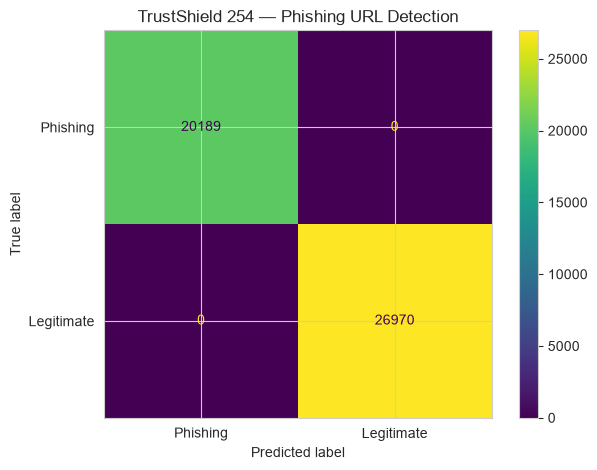

In [98]:
# Predicting labels for the test dataset
y_phishing_pred = phishing_model.predict(X_phishing_test)

# Calculating accuracy
phishing_accuracy = accuracy_score(
    y_phishing_test,
    y_phishing_pred
)

print("PHISHING URL DETECTION — MODEL EVALUATION")
print("=" * 50)
print(f"Accuracy: {phishing_accuracy:.4f} ({phishing_accuracy:.2%})")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_phishing_test,
        y_phishing_pred,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm_phishing = confusion_matrix(
    y_phishing_test,
    y_phishing_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm_phishing)

# Visualize the confusion matrix
display_phishing = ConfusionMatrixDisplay(
    confusion_matrix=cm_phishing,
    display_labels=["Phishing", "Legitimate"]
)

display_phishing.plot(values_format="d")
plt.title("TrustShield 254 — Phishing URL Detection")
plt.tight_layout()
plt.show()


### **Checking for possible data leakage**

In [99]:

# Check the relationship between phishing features and the target
# Calculate each feature's correlation with the target label
feature_correlations = (
    X_phishing_train
    .corrwith(y_phishing_train)
    .dropna()
    .sort_values(key=abs, ascending=False)
)

print("TOP 15 FEATURES MOST ASSOCIATED WITH THE TARGET")
print("=" * 55)
print(feature_correlations.head(15).to_string())

print("\nFEATURE NAMES")
print("=" * 55)
print(X_phishing_train.columns.tolist())

# Check that no original row indices occur in both splits
overlapping_indices = (
    set(X_phishing_train.index)
    & set(X_phishing_test.index)
)

print("\nTRAIN-TEST SPLIT CHECK")
print("=" * 55)
print("Overlapping row indices:", len(overlapping_indices))


TOP 15 FEATURES MOST ASSOCIATED WITH THE TARGET
URLSimilarityIndex       0.860443
HasSocialNet             0.783682
HasCopyrightInfo         0.742820
HasDescription           0.690587
IsHTTPS                  0.609105
DomainTitleMatchScore    0.583463
HasSubmitButton          0.578994
IsResponsive             0.548483
URLTitleMatchScore       0.538363
SpacialCharRatioInURL   -0.533748
HasHiddenFields          0.507307
HasFavicon               0.493375
URLCharProb              0.470242
CharContinuationRate     0.467198
HasTitle                 0.459890

FEATURE NAMES
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfC

In [100]:
# Predicting on the training and test sets
y_phishing_train_pred = phishing_model.predict(X_phishing_train)
y_phishing_test_pred = phishing_model.predict(X_phishing_test)

# Calculating accuracy for both sets
train_accuracy = accuracy_score(
    y_phishing_train,
    y_phishing_train_pred
)

test_accuracy = accuracy_score(
    y_phishing_test,
    y_phishing_test_pred
)

print("OVERFITTING DIAGNOSTIC")
print("=" * 35)
print(f"Training accuracy: {train_accuracy:.4%}")
print(f"Testing accuracy:  {test_accuracy:.4%}")
print(f"Accuracy difference: {train_accuracy - test_accuracy:.4%}")


OVERFITTING DIAGNOSTIC
Training accuracy: 100.0000%
Testing accuracy:  100.0000%
Accuracy difference: 0.0000%


In [101]:

# Checking for identical feature rows across training and test sets

train_rows = set(
    pd.util.hash_pandas_object(
        X_phishing_train,
        index=False
    ).tolist()
)

test_rows = set(
    pd.util.hash_pandas_object(
        X_phishing_test,
        index=False
    ).tolist()
)

shared_feature_rows = train_rows.intersection(test_rows)

print("DUPLICATE FEATURE-ROW CHECK")
print("=" * 40)
print("Unique training feature rows:", len(train_rows))
print("Unique testing feature rows:", len(test_rows))
print("Shared feature-row hashes:", len(shared_feature_rows))


DUPLICATE FEATURE-ROW CHECK
Unique training feature rows: 188054
Unique testing feature rows: 47101
Shared feature-row hashes: 168


In [102]:

# Investigating shared feature rows and their target labels

train_check = X_phishing_train.copy()
train_check["label"] = y_phishing_train

test_check = X_phishing_test.copy()
test_check["label"] = y_phishing_test

# Identifying feature rows that appear in both datasets
shared_train = train_check.merge(
    test_check,
    on=list(X_phishing_train.columns),
    how="inner",
    suffixes=("_train", "_test")
)

print("SHARED FEATURE-ROW INVESTIGATION")
print("=" * 45)
print("Matching row pairs:", len(shared_train))

if len(shared_train) > 0:
    label_matches = (
        shared_train["label_train"] == shared_train["label_test"]
    )

    print("Pairs with matching labels:", int(label_matches.sum()))
    print("Pairs with conflicting labels:", int((~label_matches).sum()))

    print("\nLabel combinations:")
    print(
        shared_train.groupby(
            ["label_train", "label_test"]
        ).size()
    )
else:
    print("No exact matching feature rows found.")


SHARED FEATURE-ROW INVESTIGATION
Matching row pairs: 987
Pairs with matching labels: 987
Pairs with conflicting labels: 0

Label combinations:
label_train  label_test
0            0             987
dtype: int64


In [103]:

# Counting repeated feature rows in the full phishing dataset

duplicate_mask = X_phishing_numeric.duplicated(keep=False)

duplicate_rows = int(duplicate_mask.sum())
unique_duplicate_patterns = int(
    X_phishing_numeric.loc[duplicate_mask].drop_duplicates().shape[0]
)

print("FULL DATASET DUPLICATE SUMMARY")
print("=" * 45)
print("Total records:", len(X_phishing_numeric))
print("Records belonging to repeated feature patterns:", duplicate_rows)
print("Distinct repeated feature patterns:", unique_duplicate_patterns)
print(
    "Percentage of records in repeated patterns:",
    f"{duplicate_rows / len(X_phishing_numeric) * 100:.2f}%"
)


FULL DATASET DUPLICATE SUMMARY
Total records: 235795
Records belonging to repeated feature patterns: 1292
Distinct repeated feature patterns: 484
Percentage of records in repeated patterns: 0.55%


In [105]:
# Grouping identical feature rows together
feature_groups = pd.util.hash_pandas_object(
    X_phishing_numeric,
    index=False
)

# Creating a split where each feature group belongs to one set only
group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

new_train_idx, new_test_idx = next(
    group_splitter.split(
        X_phishing_numeric,
        y_phishing,
        groups=feature_groups
    )
)

# Creating new training and testing sets
X_phishing_train_grouped = X_phishing_numeric.iloc[new_train_idx]
X_phishing_test_grouped = X_phishing_numeric.iloc[new_test_idx]

y_phishing_train_grouped = y_phishing.iloc[new_train_idx]
y_phishing_test_grouped = y_phishing.iloc[new_test_idx]

print("DUPLICATE-AWARE SPLIT")
print("=" * 45)
print("Training records:", len(X_phishing_train_grouped))
print("Testing records:", len(X_phishing_test_grouped))

# Verifying no feature-group overlap
train_groups = set(feature_groups.iloc[new_train_idx])
test_groups = set(feature_groups.iloc[new_test_idx])

print("Shared feature groups:", len(train_groups & test_groups))

print("\nTraining label distribution:")
print(y_phishing_train_grouped.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_phishing_test_grouped.value_counts().sort_index())


DUPLICATE-AWARE SPLIT
Training records: 188629
Testing records: 47166
Shared feature groups: 0

Training label distribution:
label
0     80812
1    107817
Name: count, dtype: int64

Testing label distribution:
label
0    20133
1    27033
Name: count, dtype: int64


In [106]:

# Training a fresh model using the duplicate-aware split
phishing_model_grouped = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

phishing_model_grouped.fit(
    X_phishing_train_grouped,
    y_phishing_train_grouped
)

# Evaluating on the duplicate-aware test set
y_phishing_grouped_pred = phishing_model_grouped.predict(
    X_phishing_test_grouped
)

grouped_accuracy = accuracy_score(
    y_phishing_test_grouped,
    y_phishing_grouped_pred
)

print("DUPLICATE-AWARE PHISHING MODEL EVALUATION")
print("=" * 50)
print(f"Accuracy: {grouped_accuracy:.4f} ({grouped_accuracy:.2%})")

print("\nClassification Report:")
print(
    classification_report(
        y_phishing_test_grouped,
        y_phishing_grouped_pred,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4,
        zero_division=0
    )
)

cm_grouped = confusion_matrix(
    y_phishing_test_grouped,
    y_phishing_grouped_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm_grouped)


DUPLICATE-AWARE PHISHING MODEL EVALUATION
Accuracy: 1.0000 (100.00%)

Classification Report:
                precision    recall  f1-score   support

  Phishing URL     1.0000    1.0000    1.0000     20133
Legitimate URL     1.0000    1.0000    1.0000     27033

      accuracy                         1.0000     47166
     macro avg     1.0000    1.0000    1.0000     47166
  weighted avg     1.0000    1.0000    1.0000     47166


Confusion Matrix:
[[20133     0]
 [    0 27033]]


In [ ]:

# Locating and inspecting the phishing dataset documentation
from pathlib import Path

possible_paths = [
    Path("../../Data/readme"),
    Path("../../Data/README.md"),
    Path("../../Data/README.txt"),
    Path("../../Data/Phishing_URL_Dataset_README.md"),
]

found_readme = False

for path in possible_paths:
    if path.is_file():
        print("Documentation file:", path.resolve())
        print("=" * 60)
        print(
            path.read_text(
                encoding="utf-8",
                errors="replace"
            )[:12000]
        )
        found_readme = True
        break

if not found_readme:
    print("No matching README file found.")
    print("Files in the Data folder:")

    for path in Path("../../Data").iterdir():
        print(path.name)


Documentation file: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\Data\readme
SMS Spam Collection v.1
-------------------------

1. DESCRIPTION
--------------

The SMS Spam Collection v.1 (hereafter the corpus) is a set of SMS tagged messages that have been collected for SMS Spam research. It contains one set of SMS messages in English of 5,574 messages, tagged acording being ham (legitimate) or spam. 

1.1. Compilation
----------------

This corpus has been collected from free or free for research sources at the Web:

- A collection of between 425 SMS spam messages extracted manually from the Grumbletext Web site. This is a UK forum in which cell phone users make public claims about SMS spam messages, most of them without reporting the very spam message received. The identification of the text of spam messages in the claims is a very hard and time-consuming task, and it involved carefully scanning hundreds of web pages. The Grumbletext Web site is: http://www.grumbletext.co.uk/
- A lis

In [ ]:

# Listing files in the project Data folder
data_folder = Path("../../Data")

print("PROJECT DATA FILES")
print("=" * 50)

for file_path in sorted(data_folder.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name} ({file_path.stat().st_size:,} bytes)")


PROJECT DATA FILES
community_scam_reports.csv (1,750 bytes)
fake_job_postings.csv (50,061,601 bytes)
Phishing_URL_Dataset.csv (56,854,345 bytes)
readme (5,868 bytes)
SMSSpamCollection (477,907 bytes)


In [ ]:

# Inspecting the original phishing dataset
df_phishing_source = pd.read_csv("../../Data/Phishing_URL_Dataset.csv")

print("DATASET SHAPE:", df_phishing_source.shape)

print("\nCOLUMN NAMES AND DATA TYPES")
print(df_phishing_source.dtypes.to_string())

print("\nFIRST FIVE ROWS")
display(df_phishing_source.head())

print("\nTARGET LABEL COUNTS")
print(df_phishing_source["label"].value_counts(dropna=False))

print("\nTARGET LABEL BY URL EXAMPLE")
display(df_phishing_source[["URL", "label"]].head(10))


DATASET SHAPE: (235795, 56)

COLUMN NAMES AND DATA TYPES
FILENAME                          str
URL                               str
URLLength                       int64
Domain                            str
DomainLength                    int64
IsDomainIP                      int64
TLD                               str
URLSimilarityIndex            float64
CharContinuationRate          float64
TLDLegitimateProb             float64
URLCharProb                   float64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL         f

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1



TARGET LABEL COUNTS
label
1    134850
0    100945
Name: count, dtype: int64

TARGET LABEL BY URL EXAMPLE


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1
5,https://www.globalreporting.org,1
6,https://www.saffronart.com,1
7,https://www.nerdscandy.com,1
8,https://www.hyderabadonline.in,1
9,https://www.aap.org,1


In [110]:

# Defining a URL-only feature set for a diagnostic experiment

url_only_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS",
]

# Prepare the original feature matrix using only these columns
X_url_only = df_phishing_source[url_only_features].copy()
y_url_only = df_phishing_source["label"].copy()

# Create a stratified split
from sklearn.model_selection import train_test_split

X_url_train, X_url_test, y_url_train, y_url_test = train_test_split(
    X_url_only,
    y_url_only,
    test_size=0.20,
    random_state=42,
    stratify=y_url_only
)

# Train a fresh baseline model
url_only_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

url_only_model.fit(X_url_train, y_url_train)

# Evaluate on the held-out test set
y_url_pred = url_only_model.predict(X_url_test)

print("URL-ONLY BASELINE EVALUATION")
print("=" * 45)
print(f"Accuracy: {accuracy_score(y_url_test, y_url_pred):.4%}")

print("\nClassification Report:")
print(
    classification_report(
        y_url_test,
        y_url_pred,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_url_test, y_url_pred, labels=[0, 1]))


URL-ONLY BASELINE EVALUATION
Accuracy: 99.7286%

Classification Report:
                precision    recall  f1-score   support

  Phishing URL     0.9995    0.9942    0.9968     20189
Legitimate URL     0.9956    0.9996    0.9976     26970

      accuracy                         0.9973     47159
     macro avg     0.9976    0.9969    0.9972     47159
  weighted avg     0.9973    0.9973    0.9973     47159


Confusion Matrix:
[[20071   118]
 [   10 26960]]


In [111]:

# Checking URL overlap between training and testing sets

train_urls = set(
    df_phishing_source.loc[X_url_train.index, "URL"]
    .astype(str)
    .str.strip()
    .str.lower()
)

test_urls = set(
    df_phishing_source.loc[X_url_test.index, "URL"]
    .astype(str)
    .str.strip()
    .str.lower()
)

shared_urls = train_urls.intersection(test_urls)

print("URL OVERLAP CHECK")
print("=" * 40)
print("Unique training URLs:", len(train_urls))
print("Unique testing URLs:", len(test_urls))
print("URLs present in both sets:", len(shared_urls))

print("\nExample overlapping URLs:")
for url in list(sorted(shared_urls))[:10]:
    print(url)


URL OVERLAP CHECK
Unique training URLs: 188370
Unique testing URLs: 47143
URLs present in both sets: 143

Example overlapping URLs:
http://2f3a.reicrut-chat.workers.dev/
http://akareal.com.vn/wp-admin/js/hku/sa/netfluinca/chun-g/account/sms2.php
http://app-inf0.tacbxjsspw-ypj68pkov3l2.p.temp-site.link/
http://att-107469.weeblysite.com/
http://azuki.com.co/
http://bafkreid4f4ax7k4mlmaqc6gxl256bbohhfgmjitzeiox7r6yvtkj4u7e3q.ipfs.w3s.link/
http://bet988v.com/
http://cf78105.tw1.ru/
http://dapps-connector.web.app/
http://dipartimento-revisone.com/


In [112]:

# Inspecting URLs that appear in both training and testing sets

train_url_labels = df_phishing_source.loc[
    X_url_train.index, ["URL", "label"]
].copy()

test_url_labels = df_phishing_source.loc[
    X_url_test.index, ["URL", "label"]
].copy()

# Normalizing URLs for comparison
train_url_labels["url_key"] = (
    train_url_labels["URL"].astype(str).str.strip().str.lower()
)
test_url_labels["url_key"] = (
    test_url_labels["URL"].astype(str).str.strip().str.lower()
)

shared_url_details = train_url_labels.merge(
    test_url_labels,
    on="url_key",
    suffixes=("_train", "_test")
)

print("SHARED URL LABEL CHECK")
print("=" * 40)
print("Matching URL pairs:", len(shared_url_details))

print(
    "Pairs with matching labels:",
    int(
        (
            shared_url_details["label_train"]
            == shared_url_details["label_test"]
        ).sum()
    )
)

print(
    "Pairs with conflicting labels:",
    int(
        (
            shared_url_details["label_train"]
            != shared_url_details["label_test"]
        ).sum()
    )
)

print("\nLabel combinations:")
print(
    shared_url_details.groupby(
        ["label_train", "label_test"]
    ).size()
)


SHARED URL LABEL CHECK
Matching URL pairs: 143
Pairs with matching labels: 143
Pairs with conflicting labels: 0

Label combinations:
label_train  label_test
0            0             143
dtype: int64


In [113]:
# Normalizing URLs so equivalent strings are grouped together
url_groups = (
    df_phishing_source["URL"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Keeping the URL-only features and target aligned with the original dataset
X_url_all = df_phishing_source[url_only_features].copy()
y_url_all = df_phishing_source["label"].copy()

# Splitting by URL group to prevent the same URL entering both sets
url_group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

url_train_idx, url_test_idx = next(
    url_group_splitter.split(
        X_url_all,
        y_url_all,
        groups=url_groups
    )
)

X_url_train_grouped = X_url_all.iloc[url_train_idx]
X_url_test_grouped = X_url_all.iloc[url_test_idx]

y_url_train_grouped = y_url_all.iloc[url_train_idx]
y_url_test_grouped = y_url_all.iloc[url_test_idx]

# Confirm that no normalized URL appears in both sets
train_urls_grouped = set(url_groups.iloc[url_train_idx])
test_urls_grouped = set(url_groups.iloc[url_test_idx])

print("URL-GROUPED SPLIT CHECK")
print("=" * 40)
print("Training records:", len(X_url_train_grouped))
print("Testing records:", len(X_url_test_grouped))
print("Unique training URLs:", len(train_urls_grouped))
print("Unique testing URLs:", len(test_urls_grouped))
print(
    "URLs shared between sets:",
    len(train_urls_grouped.intersection(test_urls_grouped))
)
print("\nTraining label counts:")
print(y_url_train_grouped.value_counts().sort_index())
print("\nTesting label counts:")
print(y_url_test_grouped.value_counts().sort_index())


URL-GROUPED SPLIT CHECK
Training records: 188630
Testing records: 47165
Unique training URLs: 188296
Unique testing URLs: 47074
URLs shared between sets: 0

Training label counts:
label
0     81019
1    107611
Name: count, dtype: int64

Testing label counts:
label
0    19926
1    27239
Name: count, dtype: int64


URL-GROUPED MODEL EVALUATION
Accuracy: 99.7541%

Classification Report:
                precision    recall  f1-score   support

  Phishing URL     0.9993    0.9949    0.9971     19926
Legitimate URL     0.9963    0.9995    0.9979     27239

      accuracy                         0.9975     47165
     macro avg     0.9978    0.9972    0.9975     47165
  weighted avg     0.9975    0.9975    0.9975     47165

Confusion Matrix:
[[19824   102]
 [   14 27225]]


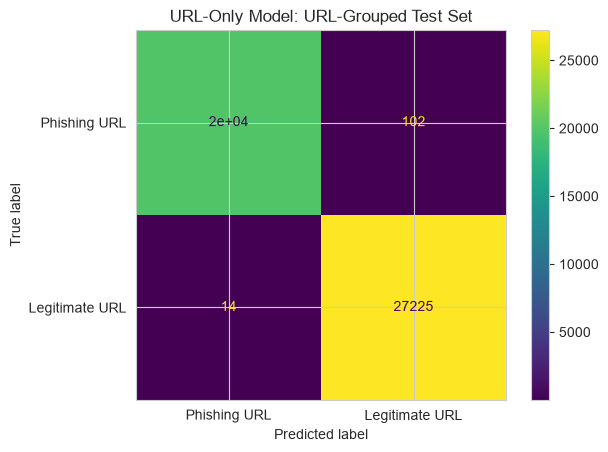

In [114]:
# Training the model using the URL-grouped training set
url_grouped_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

url_grouped_model.fit(
    X_url_train_grouped,
    y_url_train_grouped
)

# Making predictions on URLs excluded from training
y_url_grouped_pred = url_grouped_model.predict(
    X_url_test_grouped
)

# Evaluating model performance
print("URL-GROUPED MODEL EVALUATION")
print("=" * 45)

print(
    f"Accuracy: "
    f"{accuracy_score(y_url_test_grouped, y_url_grouped_pred):.4%}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_url_test_grouped,
        y_url_grouped_pred,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4
    )
)

print("Confusion Matrix:")
cm_url_grouped = confusion_matrix(
    y_url_test_grouped,
    y_url_grouped_pred,
    labels=[0, 1]
)
print(cm_url_grouped)

ConfusionMatrixDisplay(
    confusion_matrix=cm_url_grouped,
    display_labels=["Phishing URL", "Legitimate URL"]
).plot()

plt.title("URL-Only Model: URL-Grouped Test Set")
plt.show()


In [115]:

# Checking whether domains appear in both URL-grouped sets

domain_values = (
    df_phishing_source["Domain"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.rstrip(".")
)

train_domains = set(domain_values.iloc[url_train_idx].dropna())
test_domains = set(domain_values.iloc[url_test_idx].dropna())

shared_domains = train_domains.intersection(test_domains)

print("DOMAIN OVERLAP CHECK")
print("=" * 40)
print("Unique training domains:", len(train_domains))
print("Unique testing domains:", len(test_domains))
print("Domains present in both sets:", len(shared_domains))

print("\nExample overlapping domains:")
for domain in sorted(shared_domains)[:15]:
    print(domain)


DOMAIN OVERLAP CHECK
Unique training domains: 176995
Unique testing domains: 45128
Domains present in both sets: 2037

Example overlapping domains:
00-coveriy-tm.quest
0001.threepages.repl.co
010auth0.duckdns.org
041fcf0.netsolhost.com
0583z.mjt.lu
08bc6a65-b4ac-4851-9ce2-57302e775629.id.repl.co
090365bip.webcindario.com
0lx.97589584.xyz
0xm939ln.square.site
108.103.167.72.host.secureserver.net
117.6.207.182
11d409ae8e47-skirs.from-sd.com
129.226.210.78
129.226.211.41
143.198.227.120


In [116]:
# Normalizing domain values
domain_groups = (
    df_phishing_source["Domain"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.rstrip(".")
)

# Keep only rows with a known domain for this evaluation
valid_domain_mask = domain_groups.notna() & domain_groups.ne("")

X_domain = X_url_all.loc[valid_domain_mask].copy()
y_domain = y_url_all.loc[valid_domain_mask].copy()
domain_groups_valid = domain_groups.loc[valid_domain_mask]

# Split by domain, not by individual URL
domain_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

domain_train_pos, domain_test_pos = next(
    domain_splitter.split(
        X_domain,
        y_domain,
        groups=domain_groups_valid
    )
)

X_domain_train = X_domain.iloc[domain_train_pos]
X_domain_test = X_domain.iloc[domain_test_pos]

y_domain_train = y_domain.iloc[domain_train_pos]
y_domain_test = y_domain.iloc[domain_test_pos]

train_domains_final = set(
    domain_groups_valid.iloc[domain_train_pos]
)
test_domains_final = set(
    domain_groups_valid.iloc[domain_test_pos]
)

print("DOMAIN-GROUPED SPLIT CHECK")
print("=" * 40)
print("Training records:", len(X_domain_train))
print("Testing records:", len(X_domain_test))
print("Unique training domains:", len(train_domains_final))
print("Unique testing domains:", len(test_domains_final))
print(
    "Domains shared between sets:",
    len(train_domains_final.intersection(test_domains_final))
)

print("\nTraining label counts:")
print(y_domain_train.value_counts().sort_index())

print("\nTesting label counts:")
print(y_domain_test.value_counts().sort_index())


DOMAIN-GROUPED SPLIT CHECK
Training records: 189074
Testing records: 46721
Unique training domains: 176068
Unique testing domains: 44018
Domains shared between sets: 0

Training label counts:
label
0     81147
1    107927
Name: count, dtype: int64

Testing label counts:
label
0    19798
1    26923
Name: count, dtype: int64


DOMAIN-GROUPED MODEL EVALUATION
Accuracy: 99.7945%

Classification Report:
                precision    recall  f1-score   support

  Phishing URL     0.9994    0.9957    0.9976     19798
Legitimate URL     0.9969    0.9996    0.9982     26923

      accuracy                         0.9979     46721
     macro avg     0.9981    0.9976    0.9979     46721
  weighted avg     0.9979    0.9979    0.9979     46721

Confusion Matrix:
[[19713    85]
 [   11 26912]]


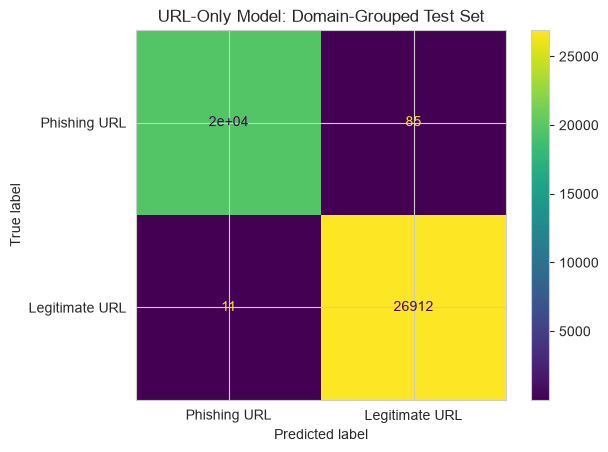

In [117]:
# Training using the domain-grouped training set
domain_grouped_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

domain_grouped_model.fit(
    X_domain_train,
    y_domain_train
)

# Predicting on domains excluded from training
y_domain_pred = domain_grouped_model.predict(X_domain_test)

# Evaluating performance
print("DOMAIN-GROUPED MODEL EVALUATION")
print("=" * 45)

print(
    f"Accuracy: "
    f"{accuracy_score(y_domain_test, y_domain_pred):.4%}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_domain_test,
        y_domain_pred,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4
    )
)

cm_domain = confusion_matrix(
    y_domain_test,
    y_domain_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm_domain)

ConfusionMatrixDisplay(
    confusion_matrix=cm_domain,
    display_labels=["Phishing URL", "Legitimate URL"]
).plot()

plt.title("URL-Only Model: Domain-Grouped Test Set")
plt.show()


URL-ONLY FEATURE CORRELATIONS WITH LABEL
IsHTTPS                       0.609132
SpacialCharRatioInURL        -0.533537
DegitRatioInURL              -0.432032
LetterRatioInURL             -0.367794
NoOfOtherSpecialCharsInURL   -0.358891
DomainLength                 -0.283152
NoOfLettersInURL             -0.258090
URLLength                    -0.233445
NoOfDegitsInURL              -0.177980
NoOfQMarkInURL               -0.175621
TLDLength                    -0.079159
NoOfEqualsInURL              -0.076963
IsDomainIP                   -0.060202
HasObfuscation               -0.052473
ObfuscationRatio             -0.041915
NoOfAmpersandInURL           -0.034622
NoOfObfuscatedChar           -0.015315
NoOfSubDomain                -0.005955


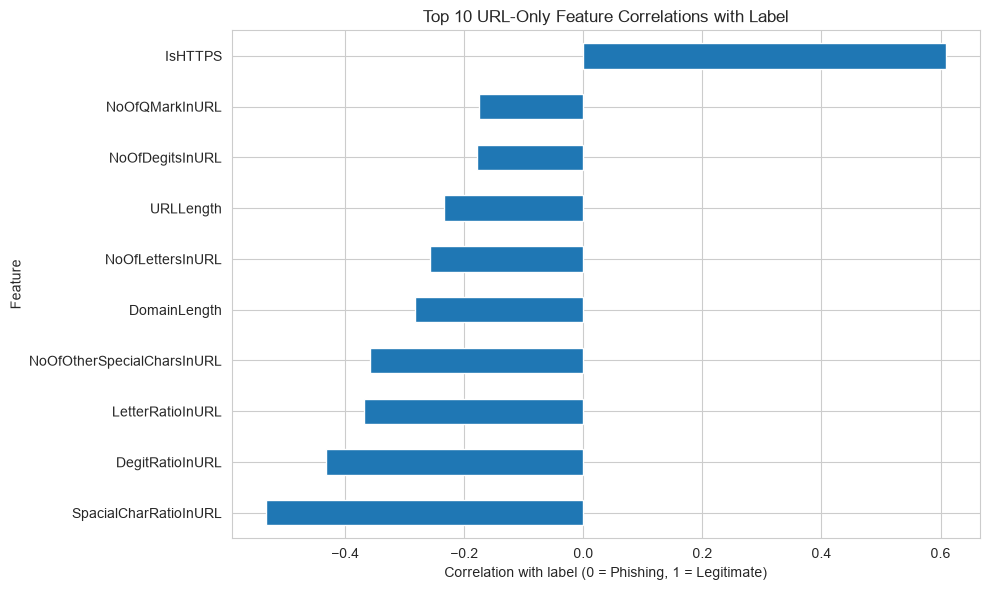

In [118]:

# Examining how strongly each URL-only feature correlates with the target

feature_correlations = (
    df_phishing_source[url_only_features + ["label"]]
    .corr(numeric_only=True)["label"]
    .drop("label")
    .sort_values(key=abs, ascending=False)
)

print("URL-ONLY FEATURE CORRELATIONS WITH LABEL")
print("=" * 50)
print(feature_correlations.to_string())

# Visualizing the strongest 10 correlations
top_correlations = feature_correlations.head(10).sort_values()

top_correlations.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 URL-Only Feature Correlations with Label")
plt.xlabel("Correlation with label (0 = Phishing, 1 = Legitimate)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [119]:

# Checking for exact duplicate columns among the URL-only features

X_url_check = df_phishing_source[url_only_features].copy()

duplicate_feature_pairs = []

for i, feature_a in enumerate(X_url_check.columns):
    for feature_b in X_url_check.columns[i + 1:]:
        if X_url_check[feature_a].equals(X_url_check[feature_b]):
            duplicate_feature_pairs.append((feature_a, feature_b))

print("EXACT DUPLICATE FEATURE CHECK")
print("=" * 45)

if duplicate_feature_pairs:
    for feature_a, feature_b in duplicate_feature_pairs:
        print(f"{feature_a} == {feature_b}")
else:
    print("No exact duplicate feature columns found.")

print("\nNumber of duplicate feature pairs:", len(duplicate_feature_pairs))


EXACT DUPLICATE FEATURE CHECK
No exact duplicate feature columns found.

Number of duplicate feature pairs: 0


In [120]:

# Identifying highly correlated URL-only features

correlation_matrix = X_url_check.corr(numeric_only=True).abs()

# Keeping only the upper triangle to avoid reporting each pair twice
upper_triangle = correlation_matrix.where(
    __import__("numpy").triu(
        __import__("numpy").ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

high_correlations = high_correlations[
    high_correlations["Absolute Correlation"] >= 0.90
].sort_values(
    "Absolute Correlation",
    ascending=False
)

print("HIGHLY CORRELATED FEATURE PAIRS")
print("=" * 45)

if high_correlations.empty:
    print("No feature pairs have an absolute correlation of 0.90 or higher.")
else:
    print(high_correlations.to_string(index=False))

print("\nNumber of highly correlated pairs:", len(high_correlations))


HIGHLY CORRELATED FEATURE PAIRS
Feature 1        Feature 2  Absolute Correlation
URLLength NoOfLettersInURL              0.956047

Number of highly correlated pairs: 1


In [122]:
# Removing only the highly correlated feature
feature_to_remove = "NoOfLettersInURL"

X_domain_train_reduced = X_domain_train.drop(
    columns=[feature_to_remove]
)
X_domain_test_reduced = X_domain_test.drop(
    columns=[feature_to_remove]
)

# Training a model using the reduced feature set
domain_model_reduced = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

domain_model_reduced.fit(
    X_domain_train_reduced,
    y_domain_train
)

# Evaluating on the same test records
y_domain_pred_reduced = domain_model_reduced.predict(
    X_domain_test_reduced
)

# Comparing results
print("FEATURE REMOVAL EXPERIMENT")
print("=" * 45)
print("Original feature count:", X_domain_train.shape[1])
print("Reduced feature count:", X_domain_train_reduced.shape[1])

print(
    "\nOriginal accuracy:",
    f"{accuracy_score(y_domain_test, y_domain_pred):.4%}"
)

print(
    "Reduced accuracy:",
    f"{accuracy_score(y_domain_test, y_domain_pred_reduced):.4%}"
)

print("\nReduced model classification report:")
print(
    classification_report(
        y_domain_test,
        y_domain_pred_reduced,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4
    )
)


FEATURE REMOVAL EXPERIMENT
Original feature count: 18
Reduced feature count: 17

Original accuracy: 99.7945%
Reduced accuracy: 99.7774%

Reduced model classification report:
                precision    recall  f1-score   support

  Phishing URL     0.9993    0.9954    0.9974     19798
Legitimate URL     0.9966    0.9995    0.9981     26923

      accuracy                         0.9978     46721
     macro avg     0.9980    0.9975    0.9977     46721
  weighted avg     0.9978    0.9978    0.9978     46721



In [123]:
data_folder = Path("../../Data")

print("DATASET DOCUMENTATION FILES")
print("=" * 45)

documentation_files = [
    path for path in data_folder.iterdir()
    if path.is_file()
    and (
        "readme" in path.name.lower()
        or "document" in path.name.lower()
        or "description" in path.name.lower()
        or path.suffix.lower() in [".md", ".txt"]
    )
]

if not documentation_files:
    print("No obvious documentation files found.")
else:
    for path in documentation_files:
        print(f"{path.name} — {path.stat().st_size:,} bytes")


DATASET DOCUMENTATION FILES
readme — 5,868 bytes


In [124]:

# Inspecting the original phishing dataset's metadata columns

print("PHISHING DATASET COLUMNS AND DATA TYPES")
print("=" * 55)

for column in df_phishing_source.columns:
    print(f"{column}: {df_phishing_source[column].dtype}")

print("\nTOTAL ROWS:", len(df_phishing_source))
print("TOTAL COLUMNS:", len(df_phishing_source.columns))


PHISHING DATASET COLUMNS AND DATA TYPES
FILENAME: str
URL: str
URLLength: int64
Domain: str
DomainLength: int64
IsDomainIP: int64
TLD: str
URLSimilarityIndex: float64
CharContinuationRate: float64
TLDLegitimateProb: float64
URLCharProb: float64
TLDLength: int64
NoOfSubDomain: int64
HasObfuscation: int64
NoOfObfuscatedChar: int64
ObfuscationRatio: float64
NoOfLettersInURL: int64
LetterRatioInURL: float64
NoOfDegitsInURL: int64
DegitRatioInURL: float64
NoOfEqualsInURL: int64
NoOfQMarkInURL: int64
NoOfAmpersandInURL: int64
NoOfOtherSpecialCharsInURL: int64
SpacialCharRatioInURL: float64
IsHTTPS: int64
LineOfCode: int64
LargestLineLength: int64
HasTitle: int64
Title: str
DomainTitleMatchScore: float64
URLTitleMatchScore: float64
HasFavicon: int64
Robots: int64
IsResponsive: int64
NoOfURLRedirect: int64
NoOfSelfRedirect: int64
HasDescription: int64
NoOfPopup: int64
NoOfiFrame: int64
HasExternalFormSubmit: int64
HasSocialNet: int64
HasSubmitButton: int64
HasHiddenFields: int64
HasPasswordFie

In [125]:

# Display ing all columns in the phishing dataset

for number, column in enumerate(df_phishing_source.columns, start=1):
    print(f"{number:02}. {column}")


01. FILENAME
02. URL
03. URLLength
04. Domain
05. DomainLength
06. IsDomainIP
07. TLD
08. URLSimilarityIndex
09. CharContinuationRate
10. TLDLegitimateProb
11. URLCharProb
12. TLDLength
13. NoOfSubDomain
14. HasObfuscation
15. NoOfObfuscatedChar
16. ObfuscationRatio
17. NoOfLettersInURL
18. LetterRatioInURL
19. NoOfDegitsInURL
20. DegitRatioInURL
21. NoOfEqualsInURL
22. NoOfQMarkInURL
23. NoOfAmpersandInURL
24. NoOfOtherSpecialCharsInURL
25. SpacialCharRatioInURL
26. IsHTTPS
27. LineOfCode
28. LargestLineLength
29. HasTitle
30. Title
31. DomainTitleMatchScore
32. URLTitleMatchScore
33. HasFavicon
34. Robots
35. IsResponsive
36. NoOfURLRedirect
37. NoOfSelfRedirect
38. HasDescription
39. NoOfPopup
40. NoOfiFrame
41. HasExternalFormSubmit
42. HasSocialNet
43. HasSubmitButton
44. HasHiddenFields
45. HasPasswordField
46. Bank
47. Pay
48. Crypto
49. HasCopyrightInfo
50. NoOfImage
51. NoOfCSS
52. NoOfJS
53. NoOfSelfRef
54. NoOfEmptyRef
55. NoOfExternalRef
56. label


In [ ]:

# Testing the URL-only model without the two features under investigation

features_to_exclude = [
    "URLSimilarityIndex",
    "TLDLegitimateProb"
]

reduced_features = [
    feature for feature in url_only_features
    if feature not in features_to_exclude
]

X_domain_train_no_suspicious = X_domain_train[reduced_features]
X_domain_test_no_suspicious = X_domain_test[reduced_features]

model_no_suspicious_features = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

model_no_suspicious_features.fit(
    X_domain_train_no_suspicious,
    y_domain_train
)

y_pred_no_suspicious = model_no_suspicious_features.predict(
    X_domain_test_no_suspicious
)

print("FEATURE EXCLUSION EXPERIMENT")
print("=" * 45)
print("Features retained:", len(reduced_features))
print("Features excluded:", features_to_exclude)

print(
    "\nOriginal domain-grouped accuracy:",
    f"{accuracy_score(y_domain_test, y_domain_pred):.4%}"
)

print(
    "Accuracy without these two features:",
    f"{accuracy_score(y_domain_test, y_pred_no_suspicious):.4%}"
)

print("\nClassification report:")
print(
    classification_report(
        y_domain_test,
        y_pred_no_suspicious,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4
    )
)


FEATURE EXCLUSION EXPERIMENT
Features retained: 18
Features excluded: ['URLSimilarityIndex', 'TLDLegitimateProb']

Original domain-grouped accuracy: 99.7945%
Accuracy without these two features: 99.7945%

Classification report:
                precision    recall  f1-score   support

  Phishing URL     0.9994    0.9957    0.9976     19798
Legitimate URL     0.9969    0.9996    0.9982     26923

      accuracy                         0.9979     46721
     macro avg     0.9981    0.9976    0.9979     46721
  weighted avg     0.9979    0.9979    0.9979     46721



In [127]:

print("FEATURES USED BY THE DOMAIN-GROUPED MODEL")
print("=" * 50)

print("Original URL-only features:", len(url_only_features))
for feature in url_only_features:
    print("-", feature)

print("\nFeatures proposed for exclusion:")
for feature in ["URLSimilarityIndex", "TLDLegitimateProb"]:
    print(
        f"{feature}:",
        "present" if feature in url_only_features else "not present"
    )


FEATURES USED BY THE DOMAIN-GROUPED MODEL
Original URL-only features: 18
- URLLength
- DomainLength
- IsDomainIP
- TLDLength
- NoOfSubDomain
- HasObfuscation
- NoOfObfuscatedChar
- ObfuscationRatio
- NoOfLettersInURL
- LetterRatioInURL
- NoOfDegitsInURL
- DegitRatioInURL
- NoOfEqualsInURL
- NoOfQMarkInURL
- NoOfAmpersandInURL
- NoOfOtherSpecialCharsInURL
- SpacialCharRatioInURL
- IsHTTPS

Features proposed for exclusion:
URLSimilarityIndex: not present
TLDLegitimateProb: not present


In [128]:

# Identifying numeric features excluded from the URL-only model

all_numeric_features = df_phishing_source.select_dtypes(
    include="number"
).columns.tolist()

all_numeric_features = [
    feature for feature in all_numeric_features
    if feature != "label"
]

non_url_numeric_features = [
    feature for feature in all_numeric_features
    if feature not in url_only_features
]

print("NUMERIC FEATURE AUDIT")
print("=" * 45)
print("All numeric features excluding target:", len(all_numeric_features))
print("URL-only features:", len(url_only_features))
print("Other numeric features:", len(non_url_numeric_features))

print("\nOther numeric features:")
for feature in non_url_numeric_features:
    print("-", feature)


NUMERIC FEATURE AUDIT
All numeric features excluding target: 50
URL-only features: 18
Other numeric features: 32

Other numeric features:
- URLSimilarityIndex
- CharContinuationRate
- TLDLegitimateProb
- URLCharProb
- LineOfCode
- LargestLineLength
- HasTitle
- DomainTitleMatchScore
- URLTitleMatchScore
- HasFavicon
- Robots
- IsResponsive
- NoOfURLRedirect
- NoOfSelfRedirect
- HasDescription
- NoOfPopup
- NoOfiFrame
- HasExternalFormSubmit
- HasSocialNet
- HasSubmitButton
- HasHiddenFields
- HasPasswordField
- Bank
- Pay
- Crypto
- HasCopyrightInfo
- NoOfImage
- NoOfCSS
- NoOfJS
- NoOfSelfRef
- NoOfEmptyRef
- NoOfExternalRef


In [129]:

print("ALL 32 ADDITIONAL NUMERIC FEATURES")
print("=" * 45)

for number, feature in enumerate(non_url_numeric_features, start=1):
    print(f"{number:02}. {feature}")


ALL 32 ADDITIONAL NUMERIC FEATURES
01. URLSimilarityIndex
02. CharContinuationRate
03. TLDLegitimateProb
04. URLCharProb
05. LineOfCode
06. LargestLineLength
07. HasTitle
08. DomainTitleMatchScore
09. URLTitleMatchScore
10. HasFavicon
11. Robots
12. IsResponsive
13. NoOfURLRedirect
14. NoOfSelfRedirect
15. HasDescription
16. NoOfPopup
17. NoOfiFrame
18. HasExternalFormSubmit
19. HasSocialNet
20. HasSubmitButton
21. HasHiddenFields
22. HasPasswordField
23. Bank
24. Pay
25. Crypto
26. HasCopyrightInfo
27. NoOfImage
28. NoOfCSS
29. NoOfJS
30. NoOfSelfRef
31. NoOfEmptyRef
32. NoOfExternalRef


In [130]:

# Summarizing the 32 additional numeric features

extra_feature_summary = df_phishing_source[
    non_url_numeric_features
].describe().T

extra_feature_summary["missing_values"] = (
    df_phishing_source[non_url_numeric_features].isna().sum()
)

extra_feature_summary["unique_values"] = (
    df_phishing_source[non_url_numeric_features].nunique()
)

print("ADDITIONAL FEATURE SUMMARY")
print("=" * 45)

print(
    extra_feature_summary[
        ["count", "mean", "std", "min", "max",
         "missing_values", "unique_values"]
    ].to_string()
)


ADDITIONAL FEATURE SUMMARY
                          count          mean            std        min           max  missing_values  unique_values
URLSimilarityIndex     235795.0     78.430778      28.976055   0.155574  1.000000e+02               0          36360
CharContinuationRate   235795.0      0.845508       0.216632   0.000000  1.000000e+00               0            898
TLDLegitimateProb      235795.0      0.260423       0.251628   0.000000  5.229071e-01               0            465
URLCharProb            235795.0      0.055747       0.010587   0.001083  9.082366e-02               0         227421
LineOfCode             235795.0   1141.900443    3419.950513   2.000000  4.426660e+05               0          10738
LargestLineLength      235795.0  12789.532624  152201.099228  22.000000  1.397573e+07               0          26181
HasTitle               235795.0      0.861261       0.345675   0.000000  1.000000e+00               0              2
DomainTitleMatchScore  235795.0     5

In [131]:

# Comparing additional feature values by target label

feature_means_by_label = (
    df_phishing_source
    .groupby("label")[non_url_numeric_features]
    .mean()
    .T
)

feature_means_by_label.columns = [
    "Phishing URL (label 0)",
    "Legitimate URL (label 1)"
]

feature_means_by_label["Absolute Mean Difference"] = (
    feature_means_by_label["Phishing URL (label 0)"]
    - feature_means_by_label["Legitimate URL (label 1)"]
).abs()

feature_means_by_label = feature_means_by_label.sort_values(
    "Absolute Mean Difference",
    ascending=False
)

print("ADDITIONAL FEATURES: MEANS BY LABEL")
print("=" * 55)
print(feature_means_by_label.to_string())


ADDITIONAL FEATURES: MEANS BY LABEL
                       Phishing URL (label 0)  Legitimate URL (label 1)  Absolute Mean Difference
LargestLineLength                20021.448244               7375.919555              12645.528689
LineOfCode                          65.730467               1947.491680               1881.761213
NoOfSelfRef                          0.496032                113.410241                112.914209
NoOfExternalRef                      1.128119                 85.294601                 84.166482
DomainTitleMatchScore               16.548205                 75.270904                 58.722698
URLTitleMatchScore                  21.198164                 75.270904                 54.072739
URLSimilarityIndex                  49.616973                100.000000                 50.383027
NoOfImage                            0.866492                 44.946600                 44.080108
NoOfJS                               0.890336                 17.732532           

In [132]:

# Inspecting URLSimilarityIndex by target label

print("URLSimilarityIndex BY LABEL")
print("=" * 45)

print(
    df_phishing_source.groupby("label")["URLSimilarityIndex"]
    .describe()
    .round(4)
)

print("\nPercentage of records with URLSimilarityIndex = 100:")
for label, name in [(0, "Phishing URL"), (1, "Legitimate URL")]:
    subset = df_phishing_source.loc[
        df_phishing_source["label"] == label,
        "URLSimilarityIndex"
    ]

    percentage = (subset.eq(100).mean()) * 100

    print(f"{name}: {percentage:.2f}%")


URLSimilarityIndex BY LABEL
          count     mean      std       min       25%       50%       75%  \
label                                                                       
0      100945.0   49.617  22.5721    0.1556   32.1206   51.4193   67.2515   
1      134850.0  100.000   0.0000  100.0000  100.0000  100.0000  100.0000   

         max  
label         
0      100.0  
1      100.0  

Percentage of records with URLSimilarityIndex = 100:
Phishing URL: 0.78%
Legitimate URL: 100.00%


In [133]:
# Using URLSimilarityIndex alone
X_similarity = df_phishing_source[["URLSimilarityIndex"]]
y_similarity = df_phishing_source["label"]

# Simple rule:
# Score = 100 predicts legitimate (1)
# Score < 100 predicts phishing (0)
y_similarity_rule = (
    df_phishing_source["URLSimilarityIndex"].eq(100)
    .astype(int)
)

print("URLSimilarityIndex SINGLE-FEATURE RULE")
print("=" * 50)

print(
    "Accuracy:",
    f"{accuracy_score(y_similarity, y_similarity_rule):.4%}"
)

print("\nClassification report:")
print(
    classification_report(
        y_similarity,
        y_similarity_rule,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_similarity, y_similarity_rule, labels=[0, 1]))


URLSimilarityIndex SINGLE-FEATURE RULE
Accuracy: 99.6667%

Classification report:
                precision    recall  f1-score   support

  Phishing URL     1.0000    0.9922    0.9961    100945
Legitimate URL     0.9942    1.0000    0.9971    134850

      accuracy                         0.9967    235795
     macro avg     0.9971    0.9961    0.9966    235795
  weighted avg     0.9967    0.9967    0.9967    235795

Confusion matrix:
[[100159    786]
 [     0 134850]]


In [135]:
# Removing URLSimilarityIndex from the existing grouped split
X_train_no_similarity = X_phishing_train_grouped.drop(
    columns=["URLSimilarityIndex"]
)
X_test_no_similarity = X_phishing_test_grouped.drop(
    columns=["URLSimilarityIndex"]
)

# Training a new model without URLSimilarityIndex
phishing_model_no_similarity = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

phishing_model_no_similarity.fit(
    X_train_no_similarity,
    y_phishing_train_grouped
)

# Making predictions
y_pred_no_similarity = phishing_model_no_similarity.predict(
    X_test_no_similarity
)

# Evaluating
print("MODEL WITHOUT URLSimilarityIndex")
print("=" * 50)

print(
    "Accuracy:",
    f"{accuracy_score(y_phishing_test_grouped, y_pred_no_similarity):.4%}"
)

print("\nClassification report:")
print(
    classification_report(
        y_phishing_test_grouped,
        y_pred_no_similarity,
        labels=[0, 1],
        target_names=["Phishing URL", "Legitimate URL"],
        digits=4
    )
)

print("Confusion matrix:")
print(
    confusion_matrix(
        y_phishing_test_grouped,
        y_pred_no_similarity,
        labels=[0, 1]
    )
)


MODEL WITHOUT URLSimilarityIndex
Accuracy: 99.9809%

Classification report:
                precision    recall  f1-score   support

  Phishing URL     1.0000    0.9996    0.9998     20133
Legitimate URL     0.9997    1.0000    0.9998     27033

      accuracy                         0.9998     47166
     macro avg     0.9998    0.9998    0.9998     47166
  weighted avg     0.9998    0.9998    0.9998     47166

Confusion matrix:
[[20125     8]
 [    1 27032]]


In [136]:

# Checking which trained models and preprocessing objects exist

objects_to_check = [
    "phishing_model",
    "phishing_model_no_similarity",
    "domain_grouped_model",
    "job_model",
    "sms_model",
    "preprocessor",
    "tfidf_vectorizer"
]

print("TRAINED MODELS AND PREPROCESSING OBJECTS")
print("=" * 50)

for object_name in objects_to_check:
    if object_name in globals():
        print(f"{object_name}: available")
    else:
        print(f"{object_name}: not found")


TRAINED MODELS AND PREPROCESSING OBJECTS
phishing_model: available
phishing_model_no_similarity: available
domain_grouped_model: available
job_model: not found
sms_model: available
preprocessor: not found
tfidf_vectorizer: not found


In [138]:
print("POSSIBLE MODELS AND PREPROCESSORS")
print("=" * 55)

for name, obj in list(globals().items()):
    try:
        if name.startswith("_"):
            continue

        if isinstance(obj, (Pipeline, ColumnTransformer, TfidfVectorizer, LogisticRegression)):
            print(f"{name}: {type(obj).__name__}")
    except Exception:
        pass


POSSIBLE MODELS AND PREPROCESSORS
jobs_preprocessor: ColumnTransformer
jobs_model: LogisticRegression
sms_vectorizer: TfidfVectorizer
sms_model: LogisticRegression


In [140]:
# Creating the models folder if it does not exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the phishing model
joblib.dump(
    domain_grouped_model,
    models_dir / "phishing_model.pkl"
)

# Save the fake-job model and its preprocessor
joblib.dump(
    jobs_model,
    models_dir / "fake_job_model.pkl"
)

joblib.dump(
    jobs_preprocessor,
    models_dir / "fake_job_preprocessor.pkl"
)

# Save the SMS spam model and its vectorizer
joblib.dump(
    sms_model,
    models_dir / "sms_spam_model.pkl"
)

joblib.dump(
    sms_vectorizer,
    models_dir / "sms_vectorizer.pkl"
)

print("Saved model files:")
for file_path in sorted(models_dir.glob("*.pkl")):
    print(f"{file_path.name} — {file_path.stat().st_size:,} bytes")


Saved model files:
fake_job_model.pkl — 120,043 bytes
fake_job_preprocessor.pkl — 508,342 bytes
phishing_model.pkl — 376,552 bytes
sms_spam_model.pkl — 41,019 bytes
sms_vectorizer.pkl — 190,935 bytes


In [141]:
models_dir = Path("../models")

model_files = [
    "phishing_model.pkl",
    "fake_job_model.pkl",
    "fake_job_preprocessor.pkl",
    "sms_spam_model.pkl",
    "sms_vectorizer.pkl"
]

print("VERIFYING SAVED MODELS")
print("=" * 45)

for filename in model_files:
    file_path = models_dir / filename
    loaded_object = joblib.load(file_path)

    print(f"OK: {filename} -> {type(loaded_object).__name__}")


VERIFYING SAVED MODELS
OK: phishing_model.pkl -> HistGradientBoostingClassifier
OK: fake_job_model.pkl -> LogisticRegression
OK: fake_job_preprocessor.pkl -> ColumnTransformer
OK: sms_spam_model.pkl -> LogisticRegression
OK: sms_vectorizer.pkl -> TfidfVectorizer


In [142]:

print("PHISHING MODEL FEATURE LIST")
print("=" * 45)

print("Number of URL-only features:", len(url_only_features))

for index, feature in enumerate(url_only_features, start=1):
    print(f"{index}. {feature}")


PHISHING MODEL FEATURE LIST
Number of URL-only features: 18
1. URLLength
2. DomainLength
3. IsDomainIP
4. TLDLength
5. NoOfSubDomain
6. HasObfuscation
7. NoOfObfuscatedChar
8. ObfuscationRatio
9. NoOfLettersInURL
10. LetterRatioInURL
11. NoOfDegitsInURL
12. DegitRatioInURL
13. NoOfEqualsInURL
14. NoOfQMarkInURL
15. NoOfAmpersandInURL
16. NoOfOtherSpecialCharsInURL
17. SpacialCharRatioInURL
18. IsHTTPS


In [143]:

import ipaddress
import re
from urllib.parse import urlsplit


def extract_url_features(url: str) -> dict:
    """
    Extract the 18 URL-based numeric features used by the
    TrustShield 254 phishing model.

    Note:
        These are transparent approximations of the dataset's
        feature definitions. Validate against the original
        feature-generation code before relying on predictions.
    """
    if not isinstance(url, str) or not url.strip():
        raise ValueError("Please provide a non-empty URL.")

    url = url.strip()

    # Allow users to enter a domain without a scheme.
    parsed = urlsplit(url if "://" in url else f"https://{url}")
    hostname = parsed.hostname or ""

    if not hostname:
        raise ValueError("The URL must contain a valid hostname.")

    full_url = url
    domain = hostname.rstrip(".")
    url_lower = full_url.lower()

    try:
        ipaddress.ip_address(domain)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    # URL character counts
    url_length = len(full_url)
    domain_length = len(domain)
    tld = domain.rsplit(".", 1)[-1] if "." in domain else ""
    tld_length = len(tld)

    domain_parts = domain.split(".")
    no_of_subdomain = max(len(domain_parts) - 2, 0)

    # Common obfuscation indicators
    obfuscated_chars = re.findall(r"%[0-9a-fA-F]{2}", full_url)
    no_of_obfuscated_char = len(obfuscated_chars)
    has_obfuscation = int(
        bool(obfuscated_chars)
        or "@" in parsed.netloc
        or "//" in parsed.path
    )
    obfuscation_ratio = no_of_obfuscated_char / max(url_length, 1)

    letters = sum(char.isalpha() for char in full_url)
    digits = sum(char.isdigit() for char in full_url)

    no_of_letters = letters
    letter_ratio = letters / max(url_length, 1)

    no_of_digits = digits
    digit_ratio = digits / max(url_length, 1)

    no_of_equals = full_url.count("=")
    no_of_qmark = full_url.count("?")
    no_of_ampersand = full_url.count("&")

    # Approximate special-character count based on URL punctuation.
    special_chars = sum(
        not char.isalnum() for char in full_url
    )
    no_of_other_special_chars = max(
        special_chars
        - full_url.count("/")
        - full_url.count(":")
        - full_url.count(".")
        - no_of_equals
        - no_of_qmark
        - no_of_ampersand,
        0
    )
    special_char_ratio = special_chars / max(url_length, 1)

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_domain_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": no_of_obfuscated_char,
        "ObfuscationRatio": obfuscation_ratio,
        "NoOfLettersInURL": no_of_letters,
        "LetterRatioInURL": letter_ratio,
        "NoOfDegitsInURL": no_of_digits,
        "DegitRatioInURL": digit_ratio,
        "NoOfEqualsInURL": no_of_equals,
        "NoOfQMarkInURL": no_of_qmark,
        "NoOfAmpersandInURL": no_of_ampersand,
        "NoOfOtherSpecialCharsInURL": no_of_other_special_chars,
        "SpacialCharRatioInURL": special_char_ratio,
        "IsHTTPS": int(parsed.scheme.lower() == "https"),
    }


In [145]:

import ipaddress
import re
from urllib.parse import urlsplit


def extract_url_features(url: str) -> dict:
    """
    Extract the 18 URL-based numeric features used by the
    TrustShield 254 phishing model.

    Note:
        These are transparent approximations of the dataset's
        feature definitions. Validate against the original
        feature-generation code before relying on predictions.
    """
    if not isinstance(url, str) or not url.strip():
        raise ValueError("Please provide a non-empty URL.")

    url = url.strip()

    # Allow users to enter a domain without a scheme.
    parsed = urlsplit(url if "://" in url else f"https://{url}")
    hostname = parsed.hostname or ""

    if not hostname:
        raise ValueError("The URL must contain a valid hostname.")

    full_url = url
    domain = hostname.rstrip(".")
    url_lower = full_url.lower()

    try:
        ipaddress.ip_address(domain)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    # URL character counts
    url_length = len(full_url)
    domain_length = len(domain)
    tld = domain.rsplit(".", 1)[-1] if "." in domain else ""
    tld_length = len(tld)

    domain_parts = domain.split(".")
    no_of_subdomain = max(len(domain_parts) - 2, 0)

    # Common obfuscation indicators
    obfuscated_chars = re.findall(r"%[0-9a-fA-F]{2}", full_url)
    no_of_obfuscated_char = len(obfuscated_chars)
    has_obfuscation = int(
        bool(obfuscated_chars)
        or "@" in parsed.netloc
        or "//" in parsed.path
    )
    obfuscation_ratio = no_of_obfuscated_char / max(url_length, 1)

    letters = sum(char.isalpha() for char in full_url)
    digits = sum(char.isdigit() for char in full_url)

    no_of_letters = letters
    letter_ratio = letters / max(url_length, 1)

    no_of_digits = digits
    digit_ratio = digits / max(url_length, 1)

    no_of_equals = full_url.count("=")
    no_of_qmark = full_url.count("?")
    no_of_ampersand = full_url.count("&")

    # Approximate special-character count based on URL punctuation.
    special_chars = sum(
        not char.isalnum() for char in full_url
    )
    no_of_other_special_chars = max(
        special_chars
        - full_url.count("/")
        - full_url.count(":")
        - full_url.count(".")
        - no_of_equals
        - no_of_qmark
        - no_of_ampersand,
        0
    )
    special_char_ratio = special_chars / max(url_length, 1)

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_domain_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": no_of_obfuscated_char,
        "ObfuscationRatio": obfuscation_ratio,
        "NoOfLettersInURL": no_of_letters,
        "LetterRatioInURL": letter_ratio,
        "NoOfDegitsInURL": no_of_digits,
        "DegitRatioInURL": digit_ratio,
        "NoOfEqualsInURL": no_of_equals,
        "NoOfQMarkInURL": no_of_qmark,
        "NoOfAmpersandInURL": no_of_ampersand,
        "NoOfOtherSpecialCharsInURL": no_of_other_special_chars,
        "SpacialCharRatioInURL": special_char_ratio,
        "IsHTTPS": int(parsed.scheme.lower() == "https"),
    }


In [147]:

from pathlib import Path

print("Notebook working directory:")
print(Path.cwd())

print("\nExpected source folder:")
src_path = Path.cwd().resolve().parents[0] / "src"
print(src_path)

print("\nDoes the source folder exist?")
print(src_path.exists())

print("\nFiles inside AI-ML/src:")
if src_path.exists():
    for file_path in src_path.iterdir():
        print(file_path.name)


Notebook working directory:
c:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\notebooks

Expected source folder:
C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\src

Does the source folder exist?
True

Files inside AI-ML/src:


In [149]:
from pathlib import Path

src_path = Path.cwd().resolve().parents[0] / "src"

print("Source file exists:", (src_path / "url_features.py").is_file())
print("Source files:", [p.name for p in src_path.iterdir()])

Source file exists: False
Source files: []


In [150]:

from pathlib import Path

src_path = Path.cwd().resolve().parents[0] / "src"
src_path.mkdir(parents=True, exist_ok=True)

file_content = '''import ipaddress
import re
from urllib.parse import urlsplit


def extract_url_features(url: str) -> dict:
    """Extract 18 approximate URL-based features for TrustShield 254."""

    if not isinstance(url, str) or not url.strip():
        raise ValueError("Please provide a non-empty URL.")

    url = url.strip()
    parsed = urlsplit(url if "://" in url else f"https://{url}")
    hostname = parsed.hostname or ""

    if not hostname:
        raise ValueError("The URL must contain a valid hostname.")

    domain = hostname.rstrip(".")
    url_length = len(url)
    domain_length = len(domain)
    tld = domain.rsplit(".", 1)[-1] if "." in domain else ""

    try:
        ipaddress.ip_address(domain)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    parts = domain.split(".")
    no_of_subdomain = max(len(parts) - 2, 0)

    obfuscated_chars = re.findall(r"%[0-9a-fA-F]{2}", url)
    no_of_obfuscated_char = len(obfuscated_chars)
    has_obfuscation = int(
        bool(obfuscated_chars)
        or "@" in parsed.netloc
        or "//" in parsed.path
    )

    letters = sum(char.isalpha() for char in url)
    digits = sum(char.isdigit() for char in url)
    special_chars = sum(not char.isalnum() for char in url)

    no_of_other_special_chars = max(
        special_chars
        - url.count("/")
        - url.count(":")
        - url.count(".")
        - url.count("=")
        - url.count("?")
        - url.count("&"),
        0
    )

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_domain_ip,
        "TLDLength": len(tld),
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": no_of_obfuscated_char,
        "ObfuscationRatio": no_of_obfuscated_char / max(url_length, 1),
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / max(url_length, 1),
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / max(url_length, 1),
        "NoOfEqualsInURL": url.count("="),
        "NoOfQMarkInURL": url.count("?"),
        "NoOfAmpersandInURL": url.count("&"),
        "NoOfOtherSpecialCharsInURL": no_of_other_special_chars,
        "SpacialCharRatioInURL": special_chars / max(url_length, 1),
        "IsHTTPS": int(parsed.scheme.lower() == "https"),
    }
'''

file_path = src_path / "url_features.py"
file_path.write_text(file_content, encoding="utf-8")

print("Created:", file_path)
print("File exists:", file_path.is_file())
print("File size:", file_path.stat().st_size, "bytes")


Created: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\src\url_features.py
File exists: True
File size: 2434 bytes


In [151]:

import sys
from pathlib import Path

src_path = Path.cwd().resolve().parents[0] / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from url_features import extract_url_features

features = extract_url_features(
    "https://example.com/login?user=test&id=123"
)

print("Feature count:", len(features))
print("\nExtracted features:")
for name, value in features.items():
    print(f"{name}: {value}")


Feature count: 18

Extracted features:
URLLength: 42
DomainLength: 11
IsDomainIP: 0
TLDLength: 3
NoOfSubDomain: 0
HasObfuscation: 0
NoOfObfuscatedChar: 0
ObfuscationRatio: 0.0
NoOfLettersInURL: 30
LetterRatioInURL: 0.7142857142857143
NoOfDegitsInURL: 3
DegitRatioInURL: 0.07142857142857142
NoOfEqualsInURL: 2
NoOfQMarkInURL: 1
NoOfAmpersandInURL: 1
NoOfOtherSpecialCharsInURL: 0
SpacialCharRatioInURL: 0.21428571428571427
IsHTTPS: 1


In [153]:

import joblib
import pandas as pd
from pathlib import Path

# Correct path: TRUSTSHIELD/AI-ML/models/
models_dir = Path.cwd().resolve().parents[0] / "models"

print("Models folder:", models_dir)
print("Folder exists:", models_dir.exists())

phishing_model_loaded = joblib.load(
    models_dir / "phishing_model.pkl"
)

# Arrange features in the original training order
X_test_url = pd.DataFrame(
    [features],
    columns=url_only_features
)

print("\nNumber of input features:", X_test_url.shape[1])
print(
    "Feature order matches training:",
    list(X_test_url.columns) == url_only_features
)

prediction = phishing_model_loaded.predict(X_test_url)

print("\nModel accepted the input successfully.")
print("Raw predicted label:", int(prediction[0]))
print("Label mapping: 0 = Phishing URL, 1 = Legitimate URL")
print("Note: This is a technical test, not a validated real-world verdict.")


Models folder: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models
Folder exists: True

Number of input features: 18
Feature order matches training: True

Model accepted the input successfully.
Raw predicted label: 0
Label mapping: 0 = Phishing URL, 1 = Legitimate URL
Note: This is a technical test, not a validated real-world verdict.


In [154]:

from pathlib import Path

src_path = Path.cwd().resolve().parents[0] / "src"

file_content = '''from pathlib import Path

import joblib
import pandas as pd

try:
    from .url_features import extract_url_features
except ImportError:
    from url_features import extract_url_features


# Resolve the models directory relative to this file.
MODELS_DIR = Path(__file__).resolve().parents[1] / "models"

_phishing_model = None
_jobs_model = None
_jobs_preprocessor = None
_sms_model = None
_sms_vectorizer = None


def load_models():
    """Load saved models once and reuse them."""
    global _phishing_model, _jobs_model, _jobs_preprocessor
    global _sms_model, _sms_vectorizer

    if _phishing_model is None:
        _phishing_model = joblib.load(
            MODELS_DIR / "phishing_model.pkl"
        )
    if _jobs_model is None:
        _jobs_model = joblib.load(
            MODELS_DIR / "fake_job_model.pkl"
        )
    if _jobs_preprocessor is None:
        _jobs_preprocessor = joblib.load(
            MODELS_DIR / "fake_job_preprocessor.pkl"
        )
    if _sms_model is None:
        _sms_model = joblib.load(
            MODELS_DIR / "sms_spam_model.pkl"
        )
    if _sms_vectorizer is None:
        _sms_vectorizer = joblib.load(
            MODELS_DIR / "sms_vectorizer.pkl"
        )


def predict_phishing_url(url: str) -> dict:
    """Return a model result for a URL.

    WARNING: URL feature calculations are approximate and must be
    validated against the original training feature definitions
    before this result is used for real-world security decisions.
    """
    load_models()
    feature_values = extract_url_features(url)
    feature_frame = pd.DataFrame([feature_values])

    prediction = int(_phishing_model.predict(feature_frame)[0])

    return {
        "prediction": prediction,
        "label": "Phishing URL" if prediction == 0 else "Legitimate URL",
        "validated_for_real_world_use": False,
        "warning": (
            "Experimental result only. URL feature calculations "
            "have not been validated against the original dataset."
        ),
    }


def predict_sms(message: str) -> dict:
    """Classify an SMS message as ham or spam."""
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please enter a message.")

    load_models()
    transformed_message = _sms_vectorizer.transform([message.strip()])
    prediction = _sms_model.predict(transformed_message)[0]

    return {
        "prediction": str(prediction),
        "label": str(prediction).upper(),
    }


def predict_job_posting(job_posting: dict) -> dict:
    """Classify a job posting using the original training preprocessor."""
    if not isinstance(job_posting, dict):
        raise ValueError("Job posting must be provided as a dictionary.")

    load_models()

    # Recreate the raw input columns expected by the preprocessor.
    input_row = pd.DataFrame([job_posting])

    # Keep the same feature columns and order used during training.
    expected_columns = list(_jobs_preprocessor.feature_names_in_)
    input_row = input_row.reindex(columns=expected_columns)

    transformed = _jobs_preprocessor.transform(input_row)
    prediction = int(_jobs_model.predict(transformed)[0])

    return {
        "prediction": prediction,
        "label": "Fraudulent job posting" if prediction == 1 else "Likely legitimate job posting",
        "validated_for_real_world_use": False,
    }
'''

file_path = src_path / "model_service.py"
file_path.write_text(file_content, encoding="utf-8")

print("Created:", file_path)
print("File exists:", file_path.is_file())
print("File size:", file_path.stat().st_size, "bytes")


Created: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\src\model_service.py
File exists: True
File size: 3477 bytes


In [156]:

import sys
from pathlib import Path

src_path = Path.cwd().resolve().parents[0] / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from model_service import load_models

print("Loading TrustShield 254 models...")
load_models()

print("\nAll model objects loaded successfully.")
print("Models directory:", src_path.parent / "models")


Loading TrustShield 254 models...

All model objects loaded successfully.
Models directory: C:\Users\User\Documents\PROJECTS\TRUSTSHIELD\AI-ML\models


In [158]:

import importlib
import model_service

importlib.reload(model_service)

job_result = model_service.predict_job_posting(sample_job)

print("FAKE JOB DETECTION")
print("=" * 40)
print(job_result)


FAKE JOB DETECTION
{'prediction': 0, 'label': 'Likely legitimate job posting', 'validated_for_real_world_use': False}


In [159]:

test_message = (
    "Congratulations! You have won a free prize. "
    "Click this link now to claim your reward."
)

sms_result = model_service.predict_sms(test_message)

print("SMS SPAM DETECTION")
print("=" * 40)
print(sms_result)


SMS SPAM DETECTION
{'prediction': 'spam', 'label': 'SPAM'}


In [160]:

normal_message = (
    "Hi, I will arrive at school at 9 AM. "
    "See you there."
)

normal_result = model_service.predict_sms(normal_message)

print("NORMAL SMS DETECTION")
print("=" * 40)
print(normal_result)


NORMAL SMS DETECTION
{'prediction': 'ham', 'label': 'HAM'}
